# E3: Keeping the subject's shadows on the new colour

**Question.** The brief asks for a parameter that keeps the subject's shadows on the new colour. Where the subject's shadow fell on the old background, the new background should get darker by the same amount; everywhere else it should stay a plain colour. How do we measure that darkening from one photo?

**Model** (Chuang et al., *Shadow Matting and Compositing*, SIGGRAPH 2003, eq. 3). A background pixel is $I = \beta L + (1-\beta) S$, with $L$ the lit background, $S$ the same background in full shadow and $\beta$ the shadow matte. If $S$ is the lit background dimmed ($S = kL$: one main light, grey ambient light), then $I / L = \beta + (1-\beta)k =: T$, and on a new colour $N$ the right pixel is $T N$. So only the **lit background $L$** has to be estimated, and $\hat T = I / \hat L$ is measured on luminance (one grey shadow for R, G and B). Chuang et al. derive it in linear light but "used the gamma-corrected pixel values directly" without visible artefacts; for a power-law gamma a ratio in sRGB is the same as in linear light, so we stay in sRGB.

The output is $\alpha \hat F + (1-\alpha)\, B_\text{new}$ (the subject layer as chosen in E2: BiRefNet's alpha and the estimated foreground). The methods differ only in the new background layer $B_\text{new}$:

| Method | Lit background $\hat L$ | New background layer |
|---|---|---|
| **A** none | none | $N$ (the pipeline after E2) |
| **B1** ratio, flat | the median luminance of the background | $\hat T N$ |
| **B2** ratio, inpainted | the photo, with the subject and a band of 10 % of the diagonal around it filled in from outside the band (OpenCV's inpainting, Telea, *J. Graphics Tools* 2004) | $\hat T N$ |
| **C** shadow as a see-through layer | as B2 | $(1-\hat T)\, I + \hat T N$: the old pixels kept with opacity $1-\hat T$, the model Chuang et al. say "does not hold for shadows" |
| **B\*** check | the true $L$ | $T N$ with the true $T$: error 0 with the true alpha (a test of this notebook); with BiRefNet's alpha, the error left by a perfect shadow map |

Fixed before the run (`bgchange/shadow.py`): the map is computed at 512 px on the long side and upsampled (shadows are smooth); $\hat T$ is measured only off the subject (alpha < 0.02, plus 1 px) and filled in under it by inpainting, so the subject's own dark pixels are not taken for a shadow; a darkening under 3 % is set to 0 (noise, JPEG, texture) and the rest rescaled (the *dead zone*); strength $s$: $T_s = 1 - s(1-\hat T)$, $s = 1$ in the main tables.

**Expected failures**, from the methods themselves: B1 takes a lighting gradient for a shadow; B2 cuts a shadow longer than its band; C leaks the old background: with the true $T$, its error in a background pixel is $T(1-T)L$ (largest at $T = 0.5$: $L/4$), the same form as E2's leak $\alpha(1-\alpha)(B-F)$.

**Data** (`data/e3_subset.md`, built by `data/make_e3_subset.py`):

| Group | n | Ground truth | Used for |
|---|---:|---|---|
| A_synthetic | 225 | exact $T$ and $L$: the 15 E2 portraits × 3 lit backgrounds (white 240, dark 64, gradient 240 → 150) × 5 shadows (none; short 2 % or long 12 % of the diagonal, hard or soft), noise σ = 2 levels | the numbers, factor by factor |
| B_desoba | 34 | $T$ from DESOBA's hand-made shadow-free photo (Hong et al., AAAI 2022), binary object mask | real shadows: soft edges, coloured light, textured ground |
| D_real | 9 | none | fashion photos, by eye |

**Metrics**, on the background pixels (true alpha < 0.02), split into **shadow** pixels ($T < 0.98$) and **lit** pixels ($T \ge 0.98$; in B also outside other objects' shadows, which are scored apart as **other**):
- Shadow map (A, B1, B2): in shadow pixels, MAE $|\hat T - T|$ and bias $\overline{\hat T - T}$ (> 0: the shadow is too light, or missed); in lit pixels, false shadow $\overline{1 - \hat T}$.
- Colour: mean absolute RGB error against the exact answer, in grey levels (0-255), on `#1E90FF` (the brief's example) and white, in the background, shadow, lit and other pixels. Each method runs with the **true alpha** (only the shadow error is left) and with **BiRefNet's alpha** and foreground estimation (the real pipeline).
- BiRefNet on shadows: the alpha it gives to shadow pixels (does it cut the shadow out with the subject?).
- Paired comparisons per portrait or photo: wins and a Wilcoxon signed-rank test (as in E1 and E2).
- Speed: seconds per image for the shadow map, on CPU.

**Hypotheses (written before the run)**
1. True alpha, flat backgrounds (white, dark), short shadows: B1 and B2 recover the shadow, MAE < 0.03 in the shadow pixels.
2. Gradient background: B1 adds a false shadow on the lit background (mean $1-\hat T$ > 0.05); B2 does not (< 0.02).
3. Long shadows on flat backgrounds: B2 misses the part outside its band, so its bias in the shadow pixels is larger than B1's.
4. With the true $T$, C's error in the shadow pixels is the predicted $T(1-T)L$ (to 0.5 grey level, the noise); with B2's $\hat T$, C is worse than B2 on every synthetic image with a shadow.
5. BiRefNet takes little of the shadow for the subject: mean alpha < 0.05 on the shadow pixels; B2's colour error in the shadow pixels with BiRefNet's alpha is within 2 grey levels of the error with the true alpha.
6. The shadow map takes under 1 s per image on CPU, at every image size of the set.
7. No-shadow controls (BiRefNet's alpha): B2 keeps a plain background plain, false shadow < 0.01 on every background.
8. DESOBA (true mask): B2 beats A in the shadow pixels on at least 28 of the 34 photos, but adds more false shadow on their textured ground than on the synthetic backgrounds.
9. Real photos, by eye: on D04 (textured ground) both B methods copy the texture; on D05 (white studio, almost no shadow) B2 changes the background by under 2 grey levels on average; on D07 and D10, B1 darkens where the light falls off, B2 less.

**Decision rule (written before the run)**
- `--keep-shadows` gets the B method with the lower background colour error on A_synthetic (BiRefNet's alpha, `#1E90FF`, all 225 inputs), unless it fails on studio backdrops (a false shadow above 0.02 on a flat or gradient background, hypotheses 2 and 7). If the paired difference is not significant (Wilcoxon p > 0.05 over the 15 portraits): B1, the simpler one (no band).
- `--keep-shadows` is off by default if keeping shadows adds error on images without a shadow (no-shadow controls, D05) or on textured backgrounds (B_desoba lit pixels): the brief asks for "a parameter".
- Default strength 1, unless the strength curve (section 7) has its lowest error at $s < 1$ on both A_synthetic and B_desoba.
- C is a baseline, not a candidate.

**Not tested**, and why: LaMa (Suvorov et al., WACV 2022) as the inpainter: on plain studio backdrops $L$ is smooth, so a neural inpainter adds little over Telea, and on textured backgrounds the ratio fails for another reason (it copies the texture); instance shadow detection (SOBA, Wang et al., CVPR 2020) to keep only the subject's shadow when other objects cast shadows; a per-channel ratio (coloured shadows).

**This run.** Google Colab (T4) through the VS Code Colab extension, images and results on Google Drive; `python experiments/fetch_e3_results.py` then copies the results into `results/e3/`. Before the run, the shadow code was tried on one portrait (34504878700), to find bugs. It found one: OpenCV 5.0's Telea inpainting leaves about half of a large float32 hole unfilled (stripes), which gave a dark halo around the subject; `bgchange/shadow.py` now inpaints through uint16. Hypotheses 1 to 6 and 9 are those of the plan of 31 Oct, thresholds unchanged. Hypotheses 7 and 8 (the no-shadow controls and DESOBA came with the data set), the alpha each hypothesis is judged with, and the 0.5-level tolerance of hypothesis 4 were written with this notebook, after that try.

**Figures.** The PPM-100 portraits and the Wikimedia Commons photos are shown as in E1 and E2. DESOBA (mixed, partly non-commercial licences) and D10 (no known licence): their figures are saved on Drive only, never shown here.

## 1. Setup

In [1]:
import importlib.util
import os
import subprocess
import sys
from pathlib import Path

# Colab runtimes ship the google.colab package (also with the VS Code extension, where it may not be imported yet).
IN_COLAB = importlib.util.find_spec("google.colab") is not None
REPO_URL = "https://github.com/MedSahbiBenKalia/modelia-bg-change"
# Smoke test: every cell on 9 images (minutes), results in results_e3/smoke/. Set True by hand, or E3_SMOKE=1.
SMOKE = os.environ.get("E3_SMOKE") == "1"


def run(cmd):
    # Like ! in a notebook, but a failure stops the notebook (a failed ! only prints and the next cells run anyway).
    r = subprocess.run([str(c) for c in cmd], capture_output=True, text=True)
    if r.returncode:
        raise RuntimeError(f"{' '.join(map(str, cmd))} failed:\n{(r.stderr or r.stdout)[-3000:]}")
    return r.stdout.strip()


if IN_COLAB:
    ROOT = Path("/content/modelia-bg-change")
    run(["git", "-C", ROOT, "pull", "-q"] if ROOT.exists() else ["git", "clone", "-q", REPO_URL, ROOT])
    from importlib import invalidate_caches
    from importlib.metadata import version
    # Keep Colab's torch (a CUDA 13 build): pin the installed torch and torchvision, so that pip stops with an error
    # instead of silently replacing them with a build for another CUDA version.
    pins = Path("/content/e3_constraints.txt")
    pins.write_text(f"torch=={version('torch')}\ntorchvision=={version('torchvision')}\n")
    # pip may upgrade a package this Python has already imported: the old copy stays in memory and later imports
    # mix two versions (seen in E1: "cannot import name '_slice'"). Detect it.
    WATCH = {"numpy": "numpy", "scipy": "scipy", "pillow": "PIL", "pandas": "pandas", "numba": "numba"}  # pip name: import name
    before = {pkg: version(pkg) for pkg, mod in WATCH.items() if mod in sys.modules}
    run([sys.executable, "-m", "pip", "install", "-q", "-r", ROOT / "requirements.txt", "-c", pins])
    invalidate_caches()
    changed = [f"{pkg} {v} -> {version(pkg)}" for pkg, v in before.items() if version(pkg) != v]
    if changed:
        raise RuntimeError(f"pip upgraded {', '.join(changed)} after it was imported: "
                           "Runtime > Restart session, then run all again (the second run installs nothing).")
else:
    # Repo root = first parent folder that holds requirements.txt (works from experiments/ or the root).
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "requirements.txt").exists())
sys.path.insert(0, str(ROOT))
COMMIT = run(["git", "-C", ROOT, "log", "-1", "--format=%h %s"])  # the code this run used
print("repo:", ROOT, "| commit:", COMMIT, "| colab:", IN_COLAB, "| smoke test:", SMOKE)

repo: /content/modelia-bg-change | commit: c0f37c3 exp(e3): shadow notebook (A none / B1 flat / B2 inpaint / C see-through), shadow map with tests, results fetch script | colab: True | smoke test: False


In [2]:
import gc
import inspect
import json
import platform
import time
from importlib.metadata import version

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from PIL import Image
from scipy.stats import wilcoxon

from bgchange.composite import over_colour
from bgchange.io import load_alpha, load_rgb, parse_hex
from bgchange.matting import estimate_foreground
from bgchange.segment import Segmenter

try:
    from bgchange.shadow import shadow_map, with_strength
    if "shade" not in inspect.signature(over_colour).parameters:
        raise ImportError("bgchange.composite.over_colour has no shade parameter")
except ImportError as e:
    raise ImportError(f"{e}. The bgchange/ in {ROOT} is older than this notebook: commit and push, then "
                      "Runtime > Restart session and run all (the setup cell pulls).") from None


def cpu_name():
    # Readable CPU model for the speed table (platform.processor() is not, on Windows).
    try:
        if sys.platform == "win32":
            import winreg
            key = winreg.OpenKey(winreg.HKEY_LOCAL_MACHINE, r"HARDWARE\DESCRIPTION\System\CentralProcessor\0")
            return winreg.QueryValueEx(key, "ProcessorNameString")[0].strip()
        return next(l.split(":", 1)[1].strip() for l in open("/proc/cpuinfo") if l.startswith("model name"))
    except Exception:
        return platform.processor() or "unknown CPU"


def cuda_works():
    """True if a small fp16 computation runs on the GPU.

    torch can see a GPU and still fail on it, at the first computation only. Colab's torch is a CUDA 13 build
    (cu130), and CUDA 13 dropped GPUs older than Turing (compute capability below 7.5, e.g. P100, V100):
    there it fails with "no kernel image is available for execution on the device".
    """
    if not torch.cuda.is_available():
        return False
    try:
        return (torch.ones(16, device="cuda", dtype=torch.float16) * 2).sum().item() == 32
    except Exception as e:
        try:
            major, minor = torch.cuda.get_device_capability()
            info = f"{torch.cuda.get_device_name()}, sm_{major}{minor}; this torch has kernels for {torch.cuda.get_arch_list()}"
        except Exception:
            info = "no device details"
        print(f"CUDA does not work here ({info}): {e!r}"[:800])
        print("Fix: connect to a T4, L4 or A100 server, or install a torch built for CUDA 12.6 "
              "(pip install torch torchvision --index-url https://download.pytorch.org/whl/cu126) and restart.")
        return False


def md_table(df: pd.DataFrame, floatfmt="{:.3f}") -> str:
    # Markdown table without the tabulate dependency.
    cols = [df.index.name or ""] + [str(c) for c in df.columns]
    lines = ["| " + " | ".join(cols) + " |", "|" + "---|" * len(cols)]
    for idx, row in df.iterrows():
        cells = [floatfmt.format(v) if isinstance(v, float) else str(v) for v in row]
        lines.append("| " + " | ".join([str(idx), *cells]) + " |")
    return "\n".join(lines)


DEVICE = "cuda" if cuda_works() else "cpu"
CPU = f"{cpu_name()} ({os.cpu_count()} threads)"
HARDWARE = torch.cuda.get_device_name() if DEVICE == "cuda" else CPU
print(f"BiRefNet on {DEVICE}: {HARDWARE} | shadow maps and foreground estimation on CPU: {CPU}")
print("torch", torch.__version__, "| CUDA", torch.version.cuda, "| transformers", version("transformers"),
      "| opencv", cv2.__version__, "| pymatting", version("pymatting"), "| numpy", np.__version__)
if IN_COLAB and DEVICE == "cpu":
    print("WARNING: BiRefNet will run on CPU, minutes per image. Pick a GPU server (a T4 is enough).")

BiRefNet on cuda: Tesla T4 | shadow maps and foreground estimation on CPU: Intel(R) Xeon(R) CPU @ 2.00GHz (2 threads)
torch 2.11.0+cu130 | CUDA 13.0 | transformers 5.21.0 | opencv 4.14.0 | pymatting 1.1.16 | numpy 2.1.3


### Data and results folders

On Colab the images come from Google Drive: the E1 folder (`modelia-e1`, also found if renamed `modelia-ai`), where `data/e3/` was uploaded as `e3/`, next to `e1/` and `e2/`. Results are written to `results_e3/` in the same folder, so they survive a disconnect. E3 needs Drive mounted: its input folders hold up to 225 files, so there is no `gdown` fallback as in E2.

Locally: `data/e3/` and `results/e3/`.

Every results folder holds at most 50 files (older `gdown` versions list no more, and `fetch_e3_results.py` lists them): the per-image outputs of A_synthetic go in one folder per portrait.

In [3]:
DRIVE_FOLDERS = ("modelia-e1", "modelia-ai")  # E1's Drive folder (e1/, e2/ and their results), or its new name


def find_e3(base: Path) -> Path | None:
    # The folder that holds A_synthetic/ and B_desoba/: normally base/e3 (the upload may have added one level).
    for cand in [base / "e3", *base.glob("*/e3"), *base.glob("e3/*")]:
        if (cand / "A_synthetic").is_dir() and (cand / "B_desoba").is_dir():
            return cand
    return None


if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    mydrive = Path("/content/drive/MyDrive")
    bases = [p for name in DRIVE_FOLDERS for p in [mydrive / name, *mydrive.glob(f"*/{name}")] if p.is_dir()]
    found = [(b, e3) for b in bases if (e3 := find_e3(b))]
    if not found:
        raise FileNotFoundError(f"no e3/ with A_synthetic/ and B_desoba/ in {[str(b) for b in bases] or DRIVE_FOLDERS}: "
                                "upload data/e3/ into the E1 Drive folder as e3/")
    base, E3_ROOT = found[0]
    RESULTS = base / "results_e3"  # next to E1's results/ and results_e2/, not inside them
else:
    E3_ROOT = ROOT / "data" / "e3"
    RESULTS = ROOT / "results" / "e3"
if SMOKE:
    RESULTS = RESULTS / "smoke"
ALPHAS = RESULTS / "alphas"          # alphas/<group>/[<portrait>/]<name>.png, 16-bit
PER_IMAGE = RESULTS / "per_image"    # per_image/<metrics|sensitivity>/<group>/<portrait or photo>.csv
FIGURES = RESULTS / "figures"
COMPOSITES = RESULTS / "composites"  # composites/<method>/<name>_<colour>.jpg, real photos only
FIGURES.mkdir(parents=True, exist_ok=True)
print("images :", E3_ROOT)
print("results:", RESULTS)

Mounted at /content/drive
images : /content/drive/MyDrive/modelia-e1/e3
results: /content/drive/MyDrive/modelia-e1/results_e3


In [4]:
subset = pd.read_csv(ROOT / "data" / "e3_subset.csv", keep_default_na=False)


def local(rel: str) -> Path:
    # CSV paths are 'e3/<group>/...' relative to data/.
    return E3_ROOT / Path(rel).relative_to("e3")


missing = sorted({p for col in ("image", "gt", "fg", "lit", "shadow", "other") for p in subset[col] if p and not local(p).exists()})
assert not missing, f"{len(missing)} files missing under {E3_ROOT} (upload not finished?), e.g. {missing[:3]}"

subset["portrait"] = [Path(f).stem if f else "" for f in subset["fg"]]  # A: the portrait the input was made from
subset["setting"] = np.where(subset["group"] == "A_synthetic", subset["background"] + " " + subset["shadow_kind"], "")
if SMOKE:
    # One portrait in 5 settings (one per hypothesis), the 2 smallest DESOBA photos, D05 (the control) and D11.
    first = subset.loc[subset["group"] == "A_synthetic", "portrait"].iloc[0]
    settings = ["white none", "white short_hard", "white long_soft", "dark short_soft", "gradient long_hard"]
    keep = (subset["portrait"] == first) & subset["setting"].isin(settings)
    photos = subset[subset["group"] == "B_desoba"]
    keep |= subset.index.isin(photos["image"].map(lambda p: local(p).stat().st_size).nsmallest(2).index)
    keep |= subset["name"].isin(["D05_jump_white_studio", "D11_studio_soft_shadow"])
    subset = subset[keep].reset_index(drop=True)

synthetic = subset[subset["group"] == "A_synthetic"]
desoba = subset[subset["group"] == "B_desoba"]
real = subset[subset["group"] == "D_real"]
scored = subset[subset["group"].isin(["A_synthetic", "B_desoba"])]  # the rows with a known answer

BACKGROUNDS = ["white", "dark", "gradient"]
KINDS = ["none", "short_hard", "short_soft", "long_hard", "long_soft"]
ENV = {"commit": COMMIT, "device": DEVICE, "hardware": HARDWARE, "cpu": CPU, "python": platform.python_version(),
       "torch": torch.__version__, "cuda": torch.version.cuda, "numpy": np.__version__, "opencv": cv2.__version__,
       **{p: version(p) for p in ("transformers", "pymatting", "numba")}}
(RESULTS / "e3_environment.json").write_text(json.dumps(ENV, indent=2), encoding="utf-8")
print(subset.groupby("group").size().to_string())

group
A_synthetic    225
B_desoba        34
D_real           9


## 2. The data (ground truth only, no model)

One portrait in its 15 synthetic versions, with the true shadow maps, shown as the darkening of the output's background $(1-\alpha)(1 - T)$ (black = lit; under the subject the map has no effect). For DESOBA, numbers only (licences); the real photos are shown except D10.

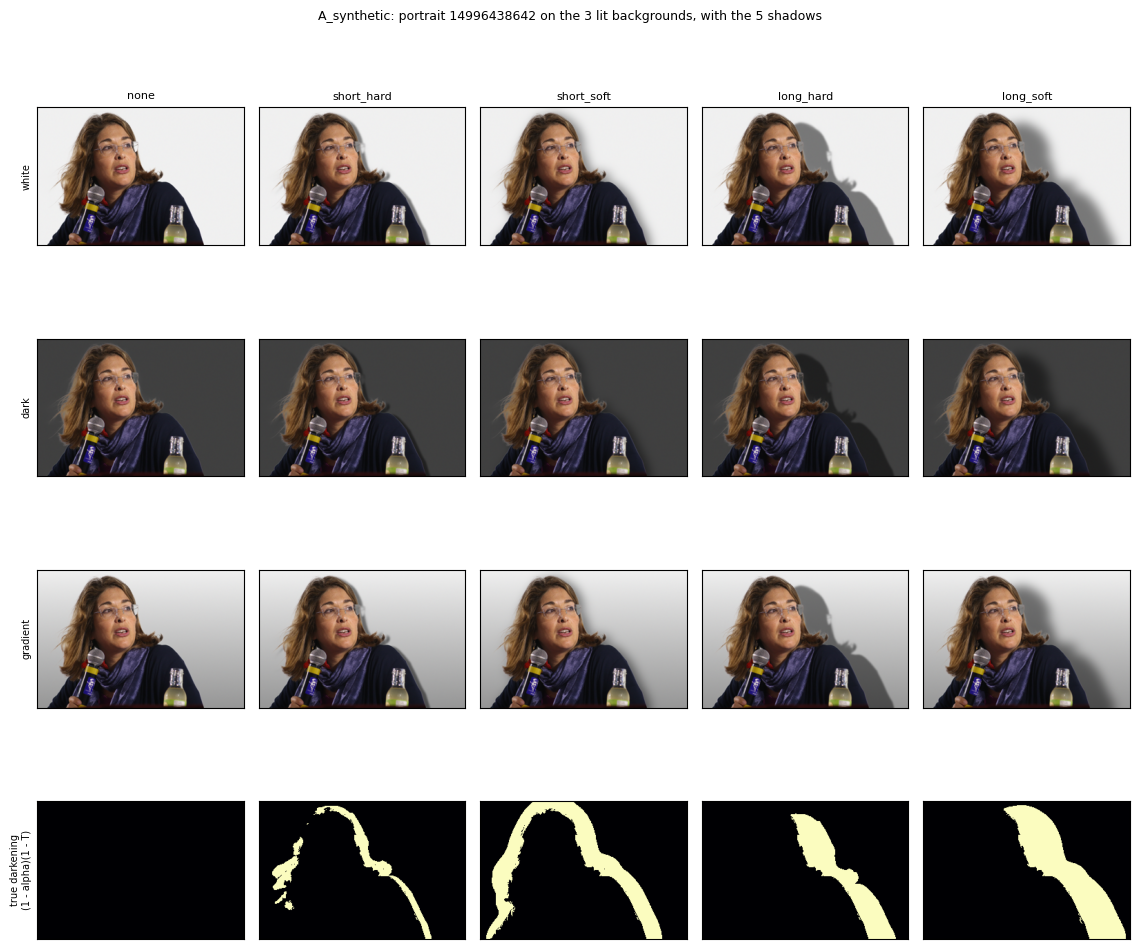

,width,height,object %,shadow %,mean T in the shadow,other shadows %
count,34.00,34.00,34.00,34.00,34.00,34.00
mean,871.53,711.62,11.93,6.03,0.41,2.31
std,319.20,293.47,7.47,6.55,0.11,8.64
min,359.00,236.00,0.93,0.57,0.17,0.00
25%,625.75,509.75,5.94,1.92,0.33,0.00
50%,895.00,683.00,11.80,4.43,0.42,0.00
75%,1024.00,832.75,15.16,6.75,0.48,0.19
max,1600.00,1365.00,32.24,31.75,0.66,48.39


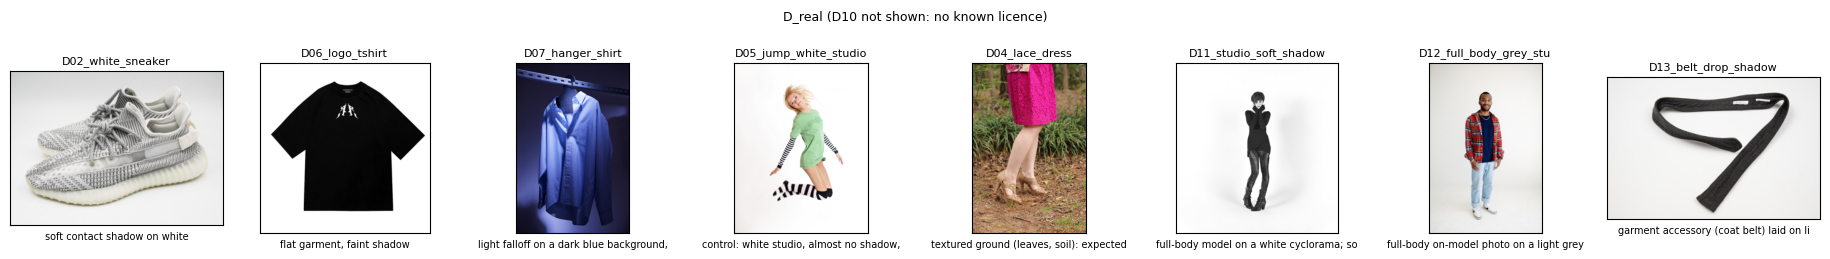

In [5]:
def thumb(a, size=512):
    """Thumbnail of an RGB image or a [0, 1] map, as an array, at most `size` px on its long side."""
    im = Image.fromarray(a if np.asarray(a).dtype == np.uint8 else (np.clip(a, 0, 1) * 255).astype(np.uint8))
    im.thumbnail((size, size))
    return np.asarray(im)


def load_map16(path):
    """A 16-bit PNG map (alpha or shadow factor) as float32 in [0, 1]."""
    a = cv2.imread(str(path), cv2.IMREAD_UNCHANGED)
    if a is None:
        raise FileNotFoundError(f"cannot read {path}")
    return a.astype(np.float32) / 65535


def load_mask(path):
    return np.asarray(Image.open(path).convert("L")) > 127


def true_shadow(r, shape):
    """The true shadow factor T of a row (1 = lit); no file means no shadow."""
    return load_map16(local(r["shadow"])) if r["shadow"] else np.ones(shape, np.float32)


def u8(a):
    return np.clip(np.asarray(a, np.float32), 0, 255).round().astype(np.uint8)


def show_grid(rows, titles, path, show=True, suptitle=None):
    """rows: (label, panels, notes). A panel: an RGB array, a 2-D map in [0, 1] (grey), ("heat", map, vmax) or None."""
    fig, axes = plt.subplots(len(rows), len(titles), figsize=(2.3 * len(titles), 2.6 * len(rows)), squeeze=False)
    for j, ax in enumerate(axes[0]):
        ax.set_title(titles[j], fontsize=8)
    for i, (label, panels, notes) in enumerate(rows):
        for j, ax in enumerate(axes[i]):
            p = panels[j] if j < len(panels) else None
            if p is None:
                ax.axis("off")
                continue
            if isinstance(p, tuple):
                ax.imshow(p[1], cmap="magma", vmin=0, vmax=p[2])
            elif np.ndim(p) == 2:
                ax.imshow(p, cmap="gray", vmin=0, vmax=255 if np.asarray(p).dtype == np.uint8 else 1)
            else:
                ax.imshow(u8(p))
            ax.set_xticks([]), ax.set_yticks([])
            if notes and j < len(notes) and notes[j]:
                ax.set_xlabel(notes[j], fontsize=7)
        axes[i][0].set_ylabel(label, fontsize=7)
    if suptitle:
        fig.suptitle(suptitle, fontsize=9)
    plt.tight_layout()
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, dpi=110)
    plt.show() if show else plt.close(fig)


# A: one portrait, its 15 inputs, then its 4 true shadow maps
if len(synthetic):
    p = synthetic["portrait"].iloc[0]
    rows_p = synthetic[synthetic["portrait"] == p].set_index("setting")
    grid = []
    for bg in BACKGROUNDS:
        grid.append((bg, [thumb(np.asarray(load_rgb(local(rows_p.loc[f"{bg} {k}", "image"]))), 300)
                          if f"{bg} {k}" in rows_p.index else None for k in KINDS], None))
    a_p = load_alpha(local(rows_p["gt"].iloc[0]))
    maps = {r["shadow_kind"]: true_shadow(r, a_p.shape) for _, r in rows_p.iterrows()}
    grid.append(("true darkening\n(1 - alpha)(1 - T)", [("heat", thumb((1 - a_p) * (1 - maps[k]), 300), 0.5) if k in maps else None
                                                          for k in KINDS], None))
    show_grid(grid, KINDS, FIGURES / "e3_data_A.png", suptitle=f"A_synthetic: portrait {p.split('_')[0]} on the 3 lit backgrounds, with the 5 shadows")

# B: numbers only
rows = []
for r in desoba.to_dict("records"):
    t = true_shadow(r, load_alpha(local(r["gt"])).shape)
    obj, oth = load_alpha(local(r["gt"])) > 0.5, load_mask(local(r["other"]))
    sh = t < 0.98
    rows.append({"name": r["name"], "width": t.shape[1], "height": t.shape[0], "object %": 100 * obj.mean(),
                 "shadow %": 100 * sh.mean(), "mean T in the shadow": float(t[sh].mean()) if sh.any() else np.nan,
                 "other shadows %": 100 * oth.mean()})
desoba_data = pd.DataFrame(rows).set_index("name")
desoba_data.to_csv(RESULTS / "e3_desoba_data.csv")
if len(desoba_data):
    display(desoba_data.describe().round(2))

# D: the photos with a known licence
shown = [r for r in real.to_dict("records") if "unknown" not in r["source"]]
if shown:
    show_grid([("", [thumb(np.asarray(load_rgb(local(r["image"]))), 300) for r in shown],
                [r["note"][:40] for r in shown])], [r["name"][:22] for r in shown], FIGURES / "e3_data_D.png",
              suptitle="D_real (D10 not shown: no known licence)")

## 3. BiRefNet alphas (GPU)

`bgchange.segment.Segmenter`, the pipeline's own code (BiRefNet at the revision pinned after E1, fp16 on the GPU), as in E2. One warm-up image (not timed), then every image is timed from PIL image in to full-size alpha out. The alpha is saved as a 16-bit PNG in `alphas/`; an image already done is skipped.

Then, against the ground truth: how much of the **shadow** does BiRefNet take for the subject (hypothesis 5)? If it gives alpha to shadow pixels, those pixels come through as subject, and the shadow is kept by the alpha whatever the shadow method.

In [6]:
def alpha_path(r):
    sub = [r["portrait"]] if r["group"] == "A_synthetic" else []  # A: one folder per portrait (15 files each)
    return ALPHAS.joinpath(r["group"], *sub, f"{r['name']}.png")


def save_alpha16(alpha, path):
    # 16-bit PNG: 8 bits round each pixel by up to 0.002, the size of BiRefNet's MAE on portraits in E1 (0.001-0.007).
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.stem + ".partial.png")
    if not cv2.imwrite(str(partial), (np.clip(alpha, 0, 1) * 65535).round().astype(np.uint16)):
        raise OSError(f"could not write {partial}")
    partial.replace(path)  # a disconnect mid-write leaves a .partial file, never a broken alpha that would be skipped


def load_alpha16(path):
    if not path.exists():
        raise FileNotFoundError(f"no alpha at {path}: run section 3 first")
    return load_map16(path)


timing_csv = RESULTS / "e3_birefnet_timing.csv"
todo = [r for r in subset.to_dict("records") if not alpha_path(r).exists()]
print(f"{len(subset) - len(todo)} alphas already done, {len(todo)} to compute on {DEVICE}")
if todo:
    t0 = time.perf_counter()
    try:
        segmenter = Segmenter(DEVICE)
    except Exception as e:
        raise RuntimeError(f"BiRefNet did not load with transformers {version('transformers')}: {e!r}. If the error comes "
                           "from the model's own code, pip install 'transformers<5', restart and run all.") from e
    load_s = time.perf_counter() - t0
    segmenter(load_rgb(local(todo[0]["image"])))  # warm-up, not timed (first-call overheads, CUDA kernel selection)
    for i, r in enumerate(todo, 1):
        img = load_rgb(local(r["image"]))
        t = time.perf_counter()
        alpha = segmenter(img)  # returns a CPU array, so the GPU work is finished when the clock stops
        row = {"name": r["name"], "group": r["group"], "megapixels": img.width * img.height / 1e6,
               "seconds": time.perf_counter() - t, "device": DEVICE, "hardware": HARDWARE, "load_seconds": load_s}
        save_alpha16(alpha, alpha_path(r))
        pd.DataFrame([row]).to_csv(timing_csv, mode="a", header=not timing_csv.exists(), index=False)
        if i % 20 == 0 or i == len(todo):
            print(f"{i}/{len(todo)} {r['name']}: {row['seconds']:.2f} s")
    del segmenter
    gc.collect()
    if DEVICE == "cuda":
        torch.cuda.empty_cache()

0 alphas already done, 268 to compute on cuda


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:138: UserWarning: 
Error while fetching `HF_TOKEN` secret value from your vault: 'Requesting secret HF_TOKEN timed out. Secrets can only be fetched when running from the Colab UI.'.
  warnings.warn(f"\nError while fetching `HF_TOKEN` secret value from your vault: '{str(e)}'.")


config.json:   0%|          | 0.00/405 [00:00<?, ?B/s]

BiRefNet_config.py:   0%|          | 0.00/298 [00:00<?, ?B/s]

birefnet.py:   0%|          | 0.00/91.9k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  444MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/754 [00:00<?, ?it/s]

20/268 19045402063_8d68cda3e2_o_white_long_soft: 0.41 s
40/268 24179781765_21532649fd_o_dark_long_soft: 0.43 s
60/268 27438080369_61ae60ab4a_o_gradient_long_soft: 0.46 s
80/268 34504878700_d626a8a3c6_o_white_long_soft: 0.44 s
100/268 35998070871_36c398b9c6_o_dark_long_soft: 0.44 s
120/268 40582488762_3ff469cfd2_o_gradient_long_soft: 0.46 s
140/268 4814717217_51bd4859dc_o_white_long_soft: 0.46 s
160/268 48624730818_67ff3c2811_o_dark_long_soft: 0.45 s
180/268 49020513826_d8fffe604d_o_gradient_long_soft: 0.44 s
200/268 5568806374_e947232b97_o_white_long_soft: 0.46 s
220/268 8881079923_af57ddb8df_o_dark_long_soft: 0.45 s
240/268 web-shadow0331: 0.45 s
260/268 D02_white_sneaker: 0.48 s
268/268 D13_belt_drop_shadow: 0.45 s


In [7]:
rows = []
for r in scored.to_dict("records"):
    gt, pred = load_alpha(local(r["gt"])), load_alpha16(alpha_path(r))
    t = true_shadow(r, gt.shape)
    bg = gt < 0.02
    sh = bg & (t < 0.98)
    rows.append({"name": r["name"], "group": r["group"], "background": r["background"], "shadow_kind": r["shadow_kind"],
                 "alpha MAE (image)": float(np.abs(pred - gt).mean()),
                 "mean alpha on shadow px": float(pred[sh].mean()) if sh.any() else np.nan,
                 "shadow px with alpha > 0.1 (%)": 100 * float((pred[sh] > 0.1).mean()) if sh.any() else np.nan,
                 "mean alpha on lit px": float(pred[bg & (t >= 0.98)].mean())})
on_shadows = pd.DataFrame(rows)
on_shadows.to_csv(RESULTS / "e3_birefnet_on_shadows.csv", index=False)
shadow_table = on_shadows.groupby(["group", "background", "shadow_kind"], sort=False).mean(numeric_only=True)
shadow_table.index = [" ".join(i) for i in shadow_table.index]
shadow_table.index.name = "BiRefNet vs the ground truth (mean)"
(RESULTS / "e3_birefnet_on_shadows.md").write_text(md_table(shadow_table, "{:.4f}"), encoding="utf-8")
display(shadow_table.round(4))

,alpha MAE (image),mean alpha on shadow px,shadow px with alpha > 0.1 (%),mean alpha on lit px
BiRefNet vs the ground truth (mean),,,,
A_synthetic white none,0.0022,NaN,NaN,0.0001
A_synthetic white short_hard,0.0025,0.0009,0.1401,0.0001
A_synthetic white short_soft,0.0024,0.0006,0.0849,0.0000
A_synthetic white long_hard,0.0024,0.0002,0.0307,0.0001
A_synthetic white long_soft,0.0024,0.0002,0.0285,0.0001
A_synthetic dark none,0.0029,NaN,NaN,0.0002
A_synthetic dark short_hard,0.0032,0.0023,0.5117,0.0001
A_synthetic dark short_soft,0.0030,0.0009,0.2065,0.0000
A_synthetic dark long_hard,0.0031,0.0004,0.0951,0.0001


## 4. Run the methods (A_synthetic, B_desoba)

For each input and each alpha source:
- **true**: the true alpha and the true foreground (A: the portrait photo; B: the photo inside the binary mask), so only the shadow method's error is left;
- **birefnet**: BiRefNet's alpha and the foreground estimated from it (E2's default), the real pipeline. The shadow maps are computed from this alpha too, since the pipeline only has it.

Every method's output on each new colour is compared with the exact answer $\alpha F + (1-\alpha) T N$. Rows are saved per portrait (A) or photo (B): a re-run after a disconnect skips what is done.

Checks first: with the true alpha, B\* (the true $T$) must give the exact answer (error 0); and C\* (C with the true $T$) gives the predicted leak $T(1-T)L$ (hypothesis 4).

The first foreground estimation compiles pymatting's numba code (or loads it from numba's disk cache): it is timed apart.

In [8]:
NEW_COLOURS = ["#1E90FF", "#FFFFFF"]  # the brief's example colour, and white (shadows show most on light colours)
LIT_METHOD = {"B1": "flat", "B2": "inpaint"}
METHODS = ["A", "B1", "B2", "C"]  # compared; B* and C* (with the true T) are checks
REGIONS = ["background", "shadow", "lit", "other"]

t = time.perf_counter()
estimate_foreground(Image.new("RGB", (64, 64)), np.full((64, 64), 0.5, np.float32))
FG_FIRST_CALL_S = time.perf_counter() - t
print(f"first foreground estimation (numba compile or cache load): {FG_FIRST_CALL_S:.1f} s")


def mean_in(v, m):
    return float(v[m].mean()) if m.any() else np.nan


def regions(a_true, t_true, other):
    """background: true alpha < 0.02; shadow: T < 0.98 there; lit: the rest of it, minus other objects' shadows (B)."""
    bg = a_true < 0.02
    return {"background": bg, "shadow": bg & (t_true < 0.98), "lit": bg & (t_true >= 0.98) & ~other, "other": bg & other}


def composites(x, f, a, maps, rgb):
    """Each method's output on the colour rgb, as float arrays of 8-bit values (rounded like the pipeline's output)."""
    out = {m: np.asarray(over_colour(f, a, rgb, None if m == "A" else maps[m]), np.float32)
           for m in ("A", "B1", "B2", "B*") if m in maps}
    xa, n = np.asarray(x, np.float32), np.array(rgb, np.float32)
    for m, t in (("C", maps["B2"]), ("C*", maps.get("B*"))):
        if t is not None:
            layer = (1 - t[..., None]) * xa + t[..., None] * n  # the old pixels kept with opacity 1 - T
            out[m] = (a[..., None] * np.asarray(f, np.float32) + (1 - a[..., None]) * layer).round()
    return out


def image_rows(r):
    x = load_rgb(local(r["image"]))
    a_true = load_alpha(local(r["gt"]))
    f_true = load_rgb(local(r["fg"])) if r["fg"] else x  # B: binary masks, the photo itself is the subject
    t_true = true_shadow(r, a_true.shape)
    lit = np.asarray(load_rgb(local(r["lit"])), np.float32)
    other = load_mask(local(r["other"])) if r["other"] else np.zeros(a_true.shape, bool)
    a_pred = load_alpha16(alpha_path(r))
    assert a_pred.shape == a_true.shape == t_true.shape == (x.height, x.width), f"{r['name']}: sizes differ"
    reg = regions(a_true, t_true, other)
    answer = {c: np.asarray(over_colour(f_true, a_true, parse_hex(c), t_true), np.float32) for c in NEW_COLOURS}
    leak = ((t_true * (1 - t_true))[..., None] * lit).mean(-1)  # C's predicted error with the true T: T(1 - T)L
    base = {k: r[k] for k in ("name", "group", "portrait", "background", "shadow_kind", "setting")}
    base["megapixels"] = x.width * x.height / 1e6
    rows = []
    for source in ("true", "birefnet"):
        if source == "true":
            a, f, fg_s = a_true, f_true, np.nan
        else:
            t = time.perf_counter()
            a, f = a_pred, estimate_foreground(x, a_pred)
            fg_s = time.perf_counter() - t
        maps, seconds = {"A": np.ones_like(a), "B*": t_true}, {}
        for m, how in LIT_METHOD.items():
            t = time.perf_counter()
            maps[m] = shadow_map(x, a, how)
            seconds[m] = time.perf_counter() - t
        for m in ("A", "B1", "B2", "B*"):
            d = maps[m] - t_true
            rows.append({**base, "kind": "map", "alpha": source, "method": m, "seconds": seconds.get(m, np.nan),
                         "fg_seconds": fg_s, "shadow_mae": mean_in(np.abs(d), reg["shadow"]),
                         "shadow_bias": mean_in(d, reg["shadow"]), "false_shadow": mean_in(1 - maps[m], reg["lit"]),
                         "other_kept": mean_in(1 - maps[m], reg["other"]), "shadow_pixels": int(reg["shadow"].sum())})
        for c in NEW_COLOURS:
            for m, out in composites(x, f, a, maps, parse_hex(c)).items():
                err = np.abs(out - answer[c]).mean(-1)
                rows += [{**base, "kind": "colour", "alpha": source, "method": m, "colour": c, "region": k,
                          "error": mean_in(err, reg[k]), "predicted": mean_in(leak, reg[k]) if m == "C*" else np.nan}
                         for k in REGIONS]
    return rows


def write_csv(df, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    partial = path.with_name(path.name + ".partial")
    df.to_csv(partial, index=False)
    partial.replace(path)


def cached_rows(path, compute):
    """Rows of one portrait or photo, saved once: a re-run after a disconnect skips what is done."""
    if path.exists():
        return pd.read_csv(path, keep_default_na=False, na_values=[""]).to_dict("records")
    rows = compute()
    write_csv(pd.DataFrame(rows), path)
    return rows


def units(d):
    """(folder, file stem, rows): one unit per portrait (A, its 15 inputs) or per photo (B)."""
    key = d["portrait"].where(d["portrait"] != "", d["name"])
    return [(g, u, part) for (g, u), part in d.groupby([d["group"], key], sort=False)]


t0 = time.perf_counter()
all_rows, todo = [], units(scored)
for i, (group, unit, part) in enumerate(todo, 1):
    all_rows += cached_rows(PER_IMAGE / "metrics" / group / f"{unit}.csv",
                            lambda part=part: [row for r in part.to_dict("records") for row in image_rows(r)])
    print(f"{i}/{len(todo)} {group}/{unit} ({time.perf_counter() - t0:.0f} s)")
results = pd.DataFrame(all_rows)
for col in ("portrait", "background", "shadow_kind", "setting"):
    results[col] = results[col].fillna("")
results.to_csv(RESULTS / "e3_metrics.csv", index=False)
maps_df = results[results["kind"] == "map"]
colour = results[results["kind"] == "colour"]

oracle = colour[(colour["method"] == "B*") & (colour["alpha"] == "true")]["error"].max()
assert oracle < 1e-6, f"B* with the true alpha is {oracle:.3f} levels off the exact answer: a bug in this notebook"
print("check passed: with the true alpha and the true T, the output is the exact answer (error 0)")
cs = colour[(colour["method"] == "C*") & (colour["alpha"] == "true") & (colour["region"] == "shadow")].dropna(subset=["error"])
print(f"C with the true T, shadow pixels (A and B): measured {cs['error'].mean():.2f} vs predicted T(1-T)L {cs['predicted'].mean():.2f} "
      f"grey levels (largest per-image gap {(cs['error'] - cs['predicted']).abs().max():.2f})")

first foreground estimation (numba compile or cache load): 47.5 s
1/49 A_synthetic/14996438642_58c976f957_o (38 s)
2/49 A_synthetic/19045402063_8d68cda3e2_o (78 s)
3/49 A_synthetic/24179781765_21532649fd_o (118 s)
4/49 A_synthetic/27438080369_61ae60ab4a_o (164 s)
5/49 A_synthetic/31137397232_5fbec8697b_o (199 s)
6/49 A_synthetic/34504878700_d626a8a3c6_o (239 s)
7/49 A_synthetic/35998070871_36c398b9c6_o (272 s)
8/49 A_synthetic/40582488762_3ff469cfd2_o (308 s)
9/49 A_synthetic/4082044950_d82c95164b_o (351 s)
10/49 A_synthetic/4814717217_51bd4859dc_o (385 s)
11/49 A_synthetic/48624730818_67ff3c2811_o (428 s)
12/49 A_synthetic/49020513826_d8fffe604d_o (485 s)
13/49 A_synthetic/49158639747_c516378273_o (520 s)
14/49 A_synthetic/5568806374_e947232b97_o (558 s)
15/49 A_synthetic/8881079923_af57ddb8df_o (591 s)
16/49 B_desoba/web-shadow0339 (596 s)
17/49 B_desoba/web-shadow0341 (599 s)
18/49 B_desoba/web-shadow0001 (603 s)
19/49 B_desoba/web-shadow0004 (607 s)
20/49 B_desoba/web-shadow0428 (6

## 5. Results

**Shadow maps** (A, B1, B2): MAE and bias in the shadow pixels, false shadow in the lit pixels; for DESOBA also the darkening kept on other objects' shadows. Method A's "MAE" is the mean darkening of the true shadow, i.e. how much shadow there is to recover.

**Colour**: mean absolute RGB error against the exact answer (grey levels), per setting, then over all of A_synthetic and over B_desoba. B\* is the error a perfect shadow map would leave.

,true shadow (A: no map),MAE B1,MAE B2,bias B1,bias B2,false B1,false B2,other kept B1,other kept B2
true alpha,,,,,,,,,
A_synthetic white none,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,NaN
A_synthetic white short_hard,0.324,0.026,0.026,0.025,0.025,0.000,0.000,NaN,NaN
A_synthetic white short_soft,0.134,0.029,0.027,0.029,0.027,0.000,0.000,NaN,NaN
A_synthetic white long_hard,0.437,0.018,0.148,0.018,0.148,0.000,0.000,NaN,NaN
A_synthetic white long_soft,0.306,0.024,0.122,0.024,0.122,0.000,0.000,NaN,NaN
A_synthetic dark none,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,NaN
A_synthetic dark short_hard,0.324,0.027,0.026,0.026,0.025,0.000,0.000,NaN,NaN
A_synthetic dark short_soft,0.134,0.030,0.026,0.030,0.026,0.000,0.000,NaN,NaN
A_synthetic dark long_hard,0.437,0.020,0.148,0.020,0.148,0.000,0.000,NaN,NaN


,true shadow (A: no map),MAE B1,MAE B2,bias B1,bias B2,false B1,false B2,other kept B1,other kept B2
birefnet alpha,,,,,,,,,
A_synthetic white none,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,NaN
A_synthetic white short_hard,0.324,0.024,0.024,0.023,0.023,0.000,0.000,NaN,NaN
A_synthetic white short_soft,0.134,0.028,0.027,0.028,0.027,0.000,0.000,NaN,NaN
A_synthetic white long_hard,0.437,0.018,0.177,0.018,0.177,0.000,0.000,NaN,NaN
A_synthetic white long_soft,0.306,0.024,0.139,0.024,0.139,0.000,0.000,NaN,NaN
A_synthetic dark none,NaN,NaN,NaN,NaN,NaN,0.000,0.000,NaN,NaN
A_synthetic dark short_hard,0.324,0.026,0.026,0.025,0.025,0.000,0.000,NaN,NaN
A_synthetic dark short_soft,0.134,0.030,0.027,0.030,0.027,0.000,0.000,NaN,NaN
A_synthetic dark long_hard,0.437,0.020,0.171,0.020,0.171,0.000,0.000,NaN,NaN


method,A,B1,B2,C,B*
"birefnet alpha, background px, on #1E90FF",,,,,
A_synthetic white none,0.02,0.02,0.02,0.02,0.02
A_synthetic white short_hard,2.48,0.21,0.20,2.36,0.02
A_synthetic white short_soft,3.43,0.78,0.74,4.12,0.02
A_synthetic white long_hard,12.20,0.50,5.09,11.24,0.02
A_synthetic white long_soft,12.19,0.96,5.58,11.85,0.02
A_synthetic dark none,0.03,0.03,0.03,0.03,0.03
A_synthetic dark short_hard,2.47,0.23,0.22,0.79,0.02
A_synthetic dark short_soft,3.43,0.85,0.74,1.64,0.02
A_synthetic dark long_hard,12.20,0.60,4.84,6.53,0.03


method,A,B1,B2,C,B*
"birefnet alpha, background px, on #FFFFFF",,,,,
A_synthetic white none,0.02,0.02,0.02,0.02,0.02
A_synthetic white short_hard,4.41,0.36,0.35,2.50,0.02
A_synthetic white short_soft,6.13,1.40,1.32,4.71,0.02
A_synthetic white long_hard,21.73,0.88,9.06,15.21,0.02
A_synthetic white long_soft,21.73,1.68,9.93,16.20,0.02
A_synthetic dark none,0.03,0.03,0.03,0.03,0.03
A_synthetic dark short_hard,4.41,0.40,0.39,0.95,0.03
A_synthetic dark short_soft,6.13,1.53,1.32,2.22,0.03
A_synthetic dark long_hard,21.73,1.04,8.61,10.30,0.03


method,A,B1,B2,C,B*
"true alpha, background px, on #1E90FF",,,,,
A_synthetic white none,0.00,0.00,0.00,0.00,0.0
A_synthetic white short_hard,2.47,0.21,0.21,2.35,0.0
A_synthetic white short_soft,3.44,0.79,0.76,4.12,0.0
A_synthetic white long_hard,12.19,0.49,3.85,11.06,0.0
A_synthetic white long_soft,12.19,0.94,4.53,11.76,0.0
A_synthetic dark none,0.00,0.00,0.00,0.00,0.0
A_synthetic dark short_hard,2.47,0.22,0.22,0.79,0.0
A_synthetic dark short_soft,3.44,0.85,0.73,1.64,0.0
A_synthetic dark long_hard,12.19,0.57,3.85,5.77,0.0


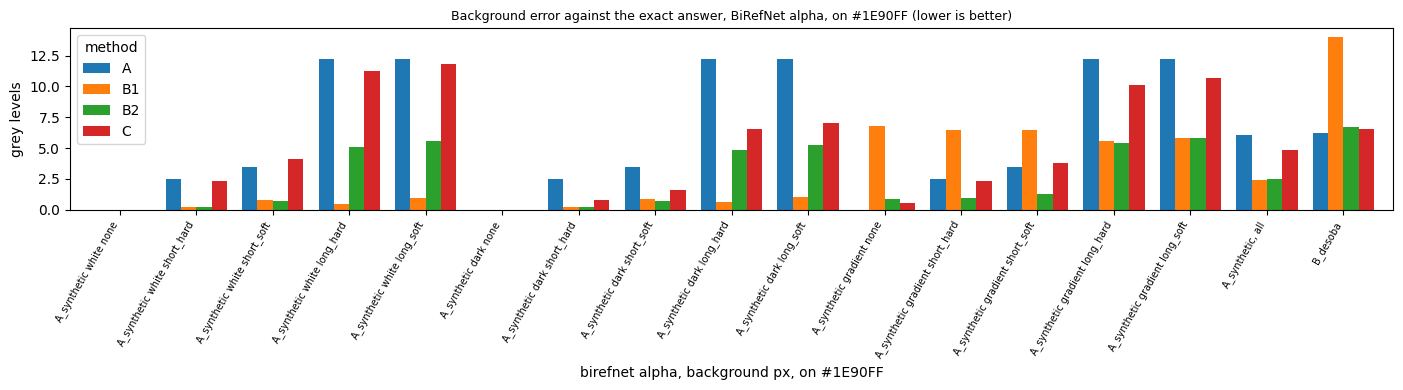

In [9]:
def setting_order(df):
    """Rows of a table in a fixed order: A settings (background x shadow), then B."""
    order = [("A_synthetic", f"{b} {k}") for b in BACKGROUNDS for k in KINDS] + [("B_desoba", "")]
    return [i for i in order if i in df.index]


def map_table(source):
    d = maps_df[(maps_df["alpha"] == source) & maps_df["method"].isin(["A", "B1", "B2"])]
    t = d.pivot_table(index=["group", "setting"], columns="method", aggfunc="mean",
                      values=["shadow_mae", "shadow_bias", "false_shadow", "other_kept"])
    t = t.loc[setting_order(t)]
    cols = [("shadow_mae", "A"), ("shadow_mae", "B1"), ("shadow_mae", "B2"), ("shadow_bias", "B1"), ("shadow_bias", "B2"),
            ("false_shadow", "B1"), ("false_shadow", "B2"), ("other_kept", "B1"), ("other_kept", "B2")]
    t = t.reindex(columns=pd.MultiIndex.from_tuples(cols))
    t.columns = ["true shadow (A: no map)", "MAE B1", "MAE B2", "bias B1", "bias B2", "false B1", "false B2",
                 "other kept B1", "other kept B2"]
    t.index = [f"{g} {s}".strip() for g, s in t.index]
    t.index.name = f"{source} alpha"
    return t


def colour_table(source, c, region):
    d = colour[(colour["alpha"] == source) & (colour["colour"] == c) & (colour["region"] == region)]
    t = d.pivot_table(index=["group", "setting"], columns="method", values="error", aggfunc="mean")
    t = t.loc[setting_order(t)].reindex(columns=METHODS + ["B*"])
    a_all = d[d["group"] == "A_synthetic"].pivot_table(columns="method", values="error", aggfunc="mean")
    t.index = [f"{g} {s}".strip() for g, s in t.index]
    if len(a_all):
        t.loc["A_synthetic, all"] = a_all.reindex(columns=METHODS + ["B*"]).iloc[0]
        t = t.loc[[i for i in t.index if i.startswith("A_")] + [i for i in t.index if i.startswith("B_")]]  # A's mean before B
    t.index.name = f"{source} alpha, {region} px, on {c}"
    return t


lines = ["Shadow maps: MAE and bias of T in the shadow pixels, false shadow (mean 1 - T) in the lit pixels.", ""]
for source in ("true", "birefnet"):
    t = map_table(source)
    display(t.round(3))
    lines += [md_table(t, "{:.3f}"), ""]
(RESULTS / "e3_map_summary.md").write_text("\n".join(lines), encoding="utf-8")

lines = ["Mean absolute RGB error against the exact answer, grey levels (0-255).", ""]
for source in ("birefnet", "true"):
    for c in NEW_COLOURS:
        for region in ("background", "shadow", "lit"):
            t = colour_table(source, c, region)
            lines += [md_table(t, "{:.2f}"), ""]
            if region == "background" and (c == NEW_COLOURS[0] or source == "birefnet"):
                display(t.round(2))
(RESULTS / "e3_colour_summary.md").write_text("\n".join(lines), encoding="utf-8")

# The main comparison as bars: background error, BiRefNet alpha, on #1E90FF
t = colour_table("birefnet", NEW_COLOURS[0], "background")[METHODS]
ax = t.plot.bar(figsize=(14, 4), width=0.8)
ax.set_ylabel("grey levels")
ax.set_title(f"Background error against the exact answer, BiRefNet alpha, on {NEW_COLOURS[0]} (lower is better)", fontsize=9)
plt.xticks(rotation=60, ha="right", fontsize=7)
plt.tight_layout()
plt.savefig(FIGURES / "e3_colour_bars.png", dpi=110)
plt.show()

## 6. Paired comparisons

Per portrait (A: the mean over its inputs in the scope) or per photo (B): mean errors, on how many the second method is better, and a Wilcoxon signed-rank test (paired, no normality assumption). Error on all background pixels, on `#1E90FF`. The no-shadow controls are kept apart: there A is right by construction.

In [10]:
COMPARE = [("B1", "B2"), ("A", "B2"), ("A", "B1"), ("C", "B2")]  # (x, y): is y better than x?


def paired(d, x, y, unit):
    w = d.pivot_table(index=unit, columns="method", values="error", aggfunc="mean")
    diff = (w[y] - w[x]).dropna()
    p = wilcoxon(diff).pvalue if len(diff) >= 5 and (diff != 0).any() else np.nan
    return {"x": x, "y": y, "n": len(diff), "mean x": w[x].mean(), "mean y": w[y].mean(),
            "y better on": int((diff < 0).sum()), "wilcoxon p": p}


main = colour[(colour["colour"] == NEW_COLOURS[0]) & (colour["region"] == "background")]
a_rows, b_rows = main[main["group"] == "A_synthetic"], main[main["group"] == "B_desoba"]
scopes = [(f"A {bg}, with a shadow", a_rows[(a_rows["background"] == bg) & (a_rows["shadow_kind"] != "none")], "portrait") for bg in BACKGROUNDS]
scopes += [(f"A {bg}, no shadow", a_rows[(a_rows["background"] == bg) & (a_rows["shadow_kind"] == "none")], "portrait") for bg in BACKGROUNDS]
scopes += [("A, all 15 settings", a_rows, "portrait"), ("B DESOBA", b_rows, "name")]
rows = [{"scope": name, "alpha": source, **paired(d[d["alpha"] == source], x, y, unit)}
        for name, d, unit in scopes if len(d) for source in ("birefnet", "true") for x, y in COMPARE]
paired_table = pd.DataFrame(rows).set_index("scope")

per_setting = [{"scope": s, "alpha": source, **paired(d[d["alpha"] == source], "B1", "B2", "portrait")}
               for s, d in a_rows.groupby("setting", sort=False) for source in ("birefnet", "true")]
per_setting = pd.DataFrame(per_setting).set_index("scope")


def p_text(df):
    out = df.copy()
    out["wilcoxon p"] = out["wilcoxon p"].map(lambda p: f"{p:.2g}")
    return out


(RESULTS / "e3_paired.md").write_text(
    f"Background error on {NEW_COLOURS[0]}, per portrait (A) or photo (B); y better on = how often y has the lower error.\n\n"
    + md_table(p_text(paired_table), "{:.3f}") + "\n\nB2 vs B1 per setting (15 portraits each):\n\n"
    + md_table(p_text(per_setting), "{:.3f}"), encoding="utf-8")
display(paired_table[paired_table["alpha"] == "birefnet"].round(3))
display(per_setting[per_setting["alpha"] == "birefnet"].round(3))

,alpha,x,y,n,mean x,mean y,y better on,wilcoxon p
scope,,,,,,,,
"A white, with a shadow",birefnet,B1,B2,15,0.612,2.902,1,0.000
"A white, with a shadow",birefnet,A,B2,15,7.576,2.902,15,0.000
"A white, with a shadow",birefnet,A,B1,15,7.576,0.612,15,0.000
"A white, with a shadow",birefnet,C,B2,15,7.391,2.902,15,0.000
"A dark, with a shadow",birefnet,B1,B2,15,0.683,2.763,1,0.000
"A dark, with a shadow",birefnet,A,B2,15,7.573,2.763,15,0.000
"A dark, with a shadow",birefnet,A,B1,15,7.573,0.683,15,0.000
"A dark, with a shadow",birefnet,C,B2,15,3.990,2.763,15,0.000
"A gradient, with a shadow",birefnet,B1,B2,15,6.099,3.363,13,0.005


,alpha,x,y,n,mean x,mean y,y better on,wilcoxon p
scope,,,,,,,,
white none,birefnet,B1,B2,15,0.022,0.022,1,0.066
white short_hard,birefnet,B1,B2,15,0.206,0.201,12,0.002
white short_soft,birefnet,B1,B2,15,0.781,0.739,15,0.000
white long_hard,birefnet,B1,B2,15,0.504,5.093,2,0.000
white long_soft,birefnet,B1,B2,15,0.956,5.575,1,0.000
dark none,birefnet,B1,B2,15,0.026,0.026,10,0.599
dark short_hard,birefnet,B1,B2,15,0.229,0.222,13,0.007
dark short_soft,birefnet,B1,B2,15,0.855,0.736,15,0.000
dark long_hard,birefnet,B1,B2,15,0.596,4.837,2,0.000


## 7. Sensitivity: dead zone, band, strength (true alpha)

The two knobs fixed by hand, varied one at a time, with the true alpha (so only the shadow map changes): the dead zone (0, 0.03, 0.06) for B1 and B2, and B2's band (5, 10, 20 % of the diagonal). Then the strength $s$ for B2 (0 = no shadow, 1 = the measured shadow). This is a check of how much the result depends on the chosen values, not a tuning: the defaults stay those fixed before the run unless a value is clearly better on both A and B.

10 units (293 s)
20 units (468 s)
30 units (487 s)
40 units (499 s)


,error 0,error 0.03,error 0.06,false_shadow 0,false_shadow 0.03,false_shadow 0.06,shadow_mae 0,shadow_mae 0.03,shadow_mae 0.06
dead_zone,,,,,,,,,
B1 A dark,0.534,0.539,0.891,0.003,0.000,0.000,0.008,0.026,0.045
B1 A gradient,7.681,6.247,5.036,0.048,0.037,0.028,0.074,0.068,0.064
B1 A white,0.134,0.487,0.844,0.001,0.000,0.000,0.004,0.024,0.043
B1 B DESOBA,15.135,13.888,12.843,0.103,0.093,0.085,0.088,0.091,0.095
B2 A dark,1.758,1.863,2.201,0.002,0.000,0.000,0.064,0.080,0.098
B2 A gradient,3.095,2.499,2.477,0.011,0.005,0.003,0.080,0.083,0.094
B2 A white,1.534,1.870,2.206,0.001,0.000,0.000,0.062,0.081,0.099
B2 B DESOBA,6.900,6.536,6.273,0.022,0.019,0.017,0.292,0.297,0.303


,error 0.05,error 0.1,error 0.2,false_shadow 0.05,false_shadow 0.1,false_shadow 0.2,shadow_mae 0.05,shadow_mae 0.1,shadow_mae 0.2
band,,,,,,,,,
B2 A dark,4.473,1.863,1.282,0.000,0.000,0.000,0.178,0.080,0.043
B2 A gradient,4.487,2.499,5.071,0.000,0.005,0.026,0.177,0.083,0.072
B2 A white,4.482,1.870,1.283,0.000,0.000,0.000,0.178,0.081,0.044
B2 B DESOBA,6.047,6.536,9.192,0.008,0.019,0.046,0.418,0.297,0.187


,error 0,error 0.25,error 0.5,error 0.75,error 1,false_shadow 0,false_shadow 0.25,false_shadow 0.5,false_shadow 0.75,false_shadow 1,shadow_mae 0,shadow_mae 0.25,shadow_mae 0.5,shadow_mae 0.75,shadow_mae 1
strength,,,,,,,,,,,,,,,
B2 A dark,6.057,5.008,3.962,2.910,1.863,0.0,0.000,0.000,0.000,0.000,0.300,0.245,0.190,0.135,0.080
B2 A gradient,6.057,5.060,4.101,3.184,2.499,0.0,0.001,0.002,0.004,0.005,0.300,0.242,0.184,0.128,0.083
B2 A white,6.057,5.010,3.964,2.916,1.870,0.0,0.000,0.000,0.000,0.000,0.300,0.245,0.190,0.135,0.081
B2 B DESOBA,6.077,6.164,6.263,6.371,6.536,0.0,0.005,0.010,0.014,0.019,0.589,0.513,0.437,0.363,0.297


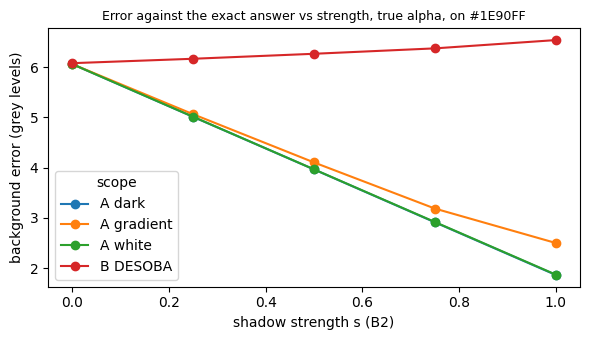

In [11]:
DEFAULTS = {"margin": 0.10, "dead_zone": 0.03}
VARIANTS = [("dead_zone", m, v) for m in ("B1", "B2") for v in (0.0, 0.03, 0.06)] + [("band", "B2", v) for v in (0.05, 0.10, 0.20)]
STRENGTHS = [0.0, 0.25, 0.5, 0.75, 1.0]


def sensitivity_rows(r):
    x = load_rgb(local(r["image"]))
    a = load_alpha(local(r["gt"]))
    f = load_rgb(local(r["fg"])) if r["fg"] else x
    t_true = true_shadow(r, a.shape)
    reg = regions(a, t_true, load_mask(local(r["other"])) if r["other"] else np.zeros(a.shape, bool))
    rgb = parse_hex(NEW_COLOURS[0])
    answer = np.asarray(over_colour(f, a, rgb, t_true), np.float32)
    base = {k: r[k] for k in ("name", "group", "portrait", "background", "shadow_kind", "setting")}
    rows, maps = [], {}

    def score(param, m, v, t):
        d = t - t_true
        err = np.abs(np.asarray(over_colour(f, a, rgb, t), np.float32) - answer).mean(-1)
        rows.append({**base, "param": param, "method": m, "value": v, "shadow_mae": mean_in(np.abs(d), reg["shadow"]),
                     "shadow_bias": mean_in(d, reg["shadow"]), "false_shadow": mean_in(1 - t, reg["lit"]),
                     "error": mean_in(err, reg["background"])})

    for param, m, v in VARIANTS:
        kw = {**DEFAULTS, ("dead_zone" if param == "dead_zone" else "margin"): v}
        key = (LIT_METHOD[m], kw["margin"], kw["dead_zone"])
        if key not in maps:
            maps[key] = shadow_map(x, a, LIT_METHOD[m], **kw)
        score(param, m, v, maps[key])
    for s in STRENGTHS:
        score("strength", "B2", s, with_strength(maps[("inpaint", 0.10, 0.03)], s))
    return rows


t0 = time.perf_counter()
sens = []
for i, (group, unit, part) in enumerate(units(scored), 1):
    sens += cached_rows(PER_IMAGE / "sensitivity" / group / f"{unit}.csv",
                        lambda part=part: [row for r in part.to_dict("records") for row in sensitivity_rows(r)])
    if i % 10 == 0:
        print(f"{i} units ({time.perf_counter() - t0:.0f} s)")
sens = pd.DataFrame(sens)
for col in ("portrait", "background", "shadow_kind", "setting"):
    sens[col] = sens[col].fillna("")
sens.to_csv(RESULTS / "e3_sensitivity.csv", index=False)
sens["scope"] = np.where(sens["group"] == "A_synthetic", "A " + sens["background"], "B DESOBA")

lines = [f"True alpha. error = background error on {NEW_COLOURS[0]} (grey levels); false = false shadow; MAE = shadow MAE.", ""]
for param in ("dead_zone", "band", "strength"):
    d = sens[sens["param"] == param]
    t = d.pivot_table(index=["method", "scope"], columns="value", values=["error", "false_shadow", "shadow_mae"], aggfunc="mean")
    t.columns = [f"{metric} {v:g}" for metric, v in t.columns]
    t.index = [f"{m} {s}" for m, s in t.index]
    t.index.name = param
    lines += [md_table(t, "{:.3f}"), ""]
    display(t.round(3))
(RESULTS / "e3_sensitivity.md").write_text("\n".join(lines), encoding="utf-8")

curve = sens[sens["param"] == "strength"].pivot_table(index="value", columns="scope", values="error", aggfunc="mean")
ax = curve.plot(marker="o", figsize=(6, 3.5))
ax.set_xlabel("shadow strength s (B2)")
ax.set_ylabel("background error (grey levels)")
ax.set_title(f"Error against the exact answer vs strength, true alpha, on {NEW_COLOURS[0]}", fontsize=9)
plt.tight_layout()
plt.savefig(FIGURES / "e3_strength_curve.png", dpi=110)
plt.show()

## 8. Figures

**A_synthetic**, BiRefNet's alpha (what the pipeline does), on `#1E90FF`: two portraits chosen by rule, not by eye (the highest and the median B2 background error), in 5 settings that cover the hypotheses. Maps show the darkening the output's background gets, $(1-\alpha)(1-T)$ (0 to 0.5; the true alpha for the true map, BiRefNet's for the estimates); the error map is $|B2 - \text{answer}|$ on the background pixels, where the numbers are taken (0 to 32 grey levels).

**B_desoba**, true mask: the 3 photos with the highest and the 3 with the lowest B2 error. Saved on Drive only.

**D_real**, BiRefNet's alpha: each method on `#1E90FF`, and the full composites (at most 1600 px) on `#1E90FF` and white in `composites/<method>/`. Without ground truth, the numbers are the share of background (BiRefNet alpha < 0.02) that each map darkens, its mean darkening, and the mean change from A on white. Then the strength $s$ on two studio photos.

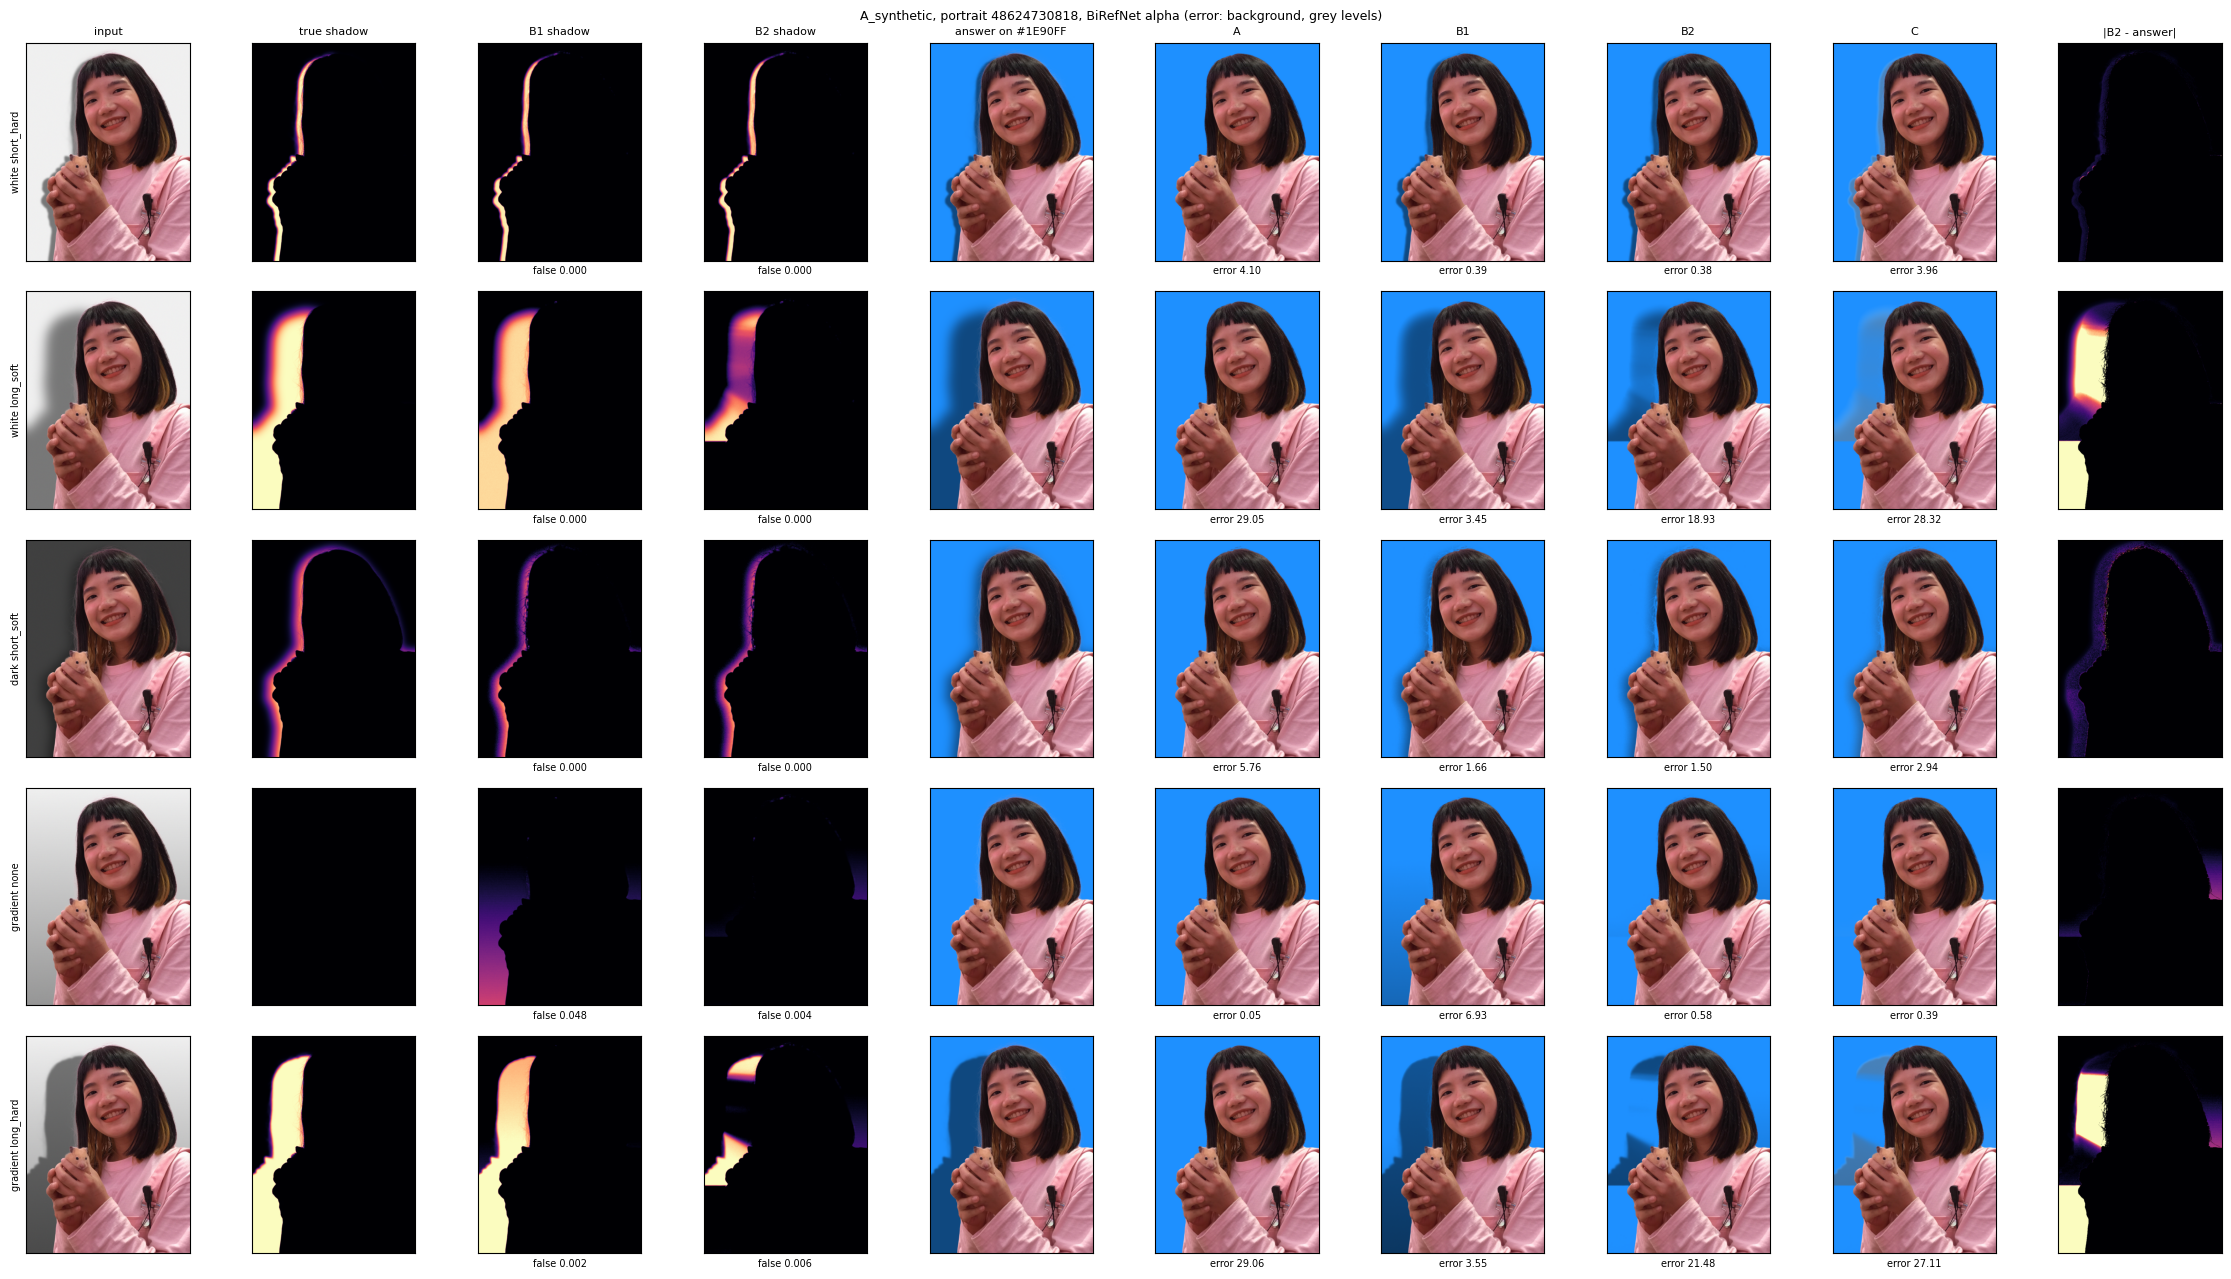

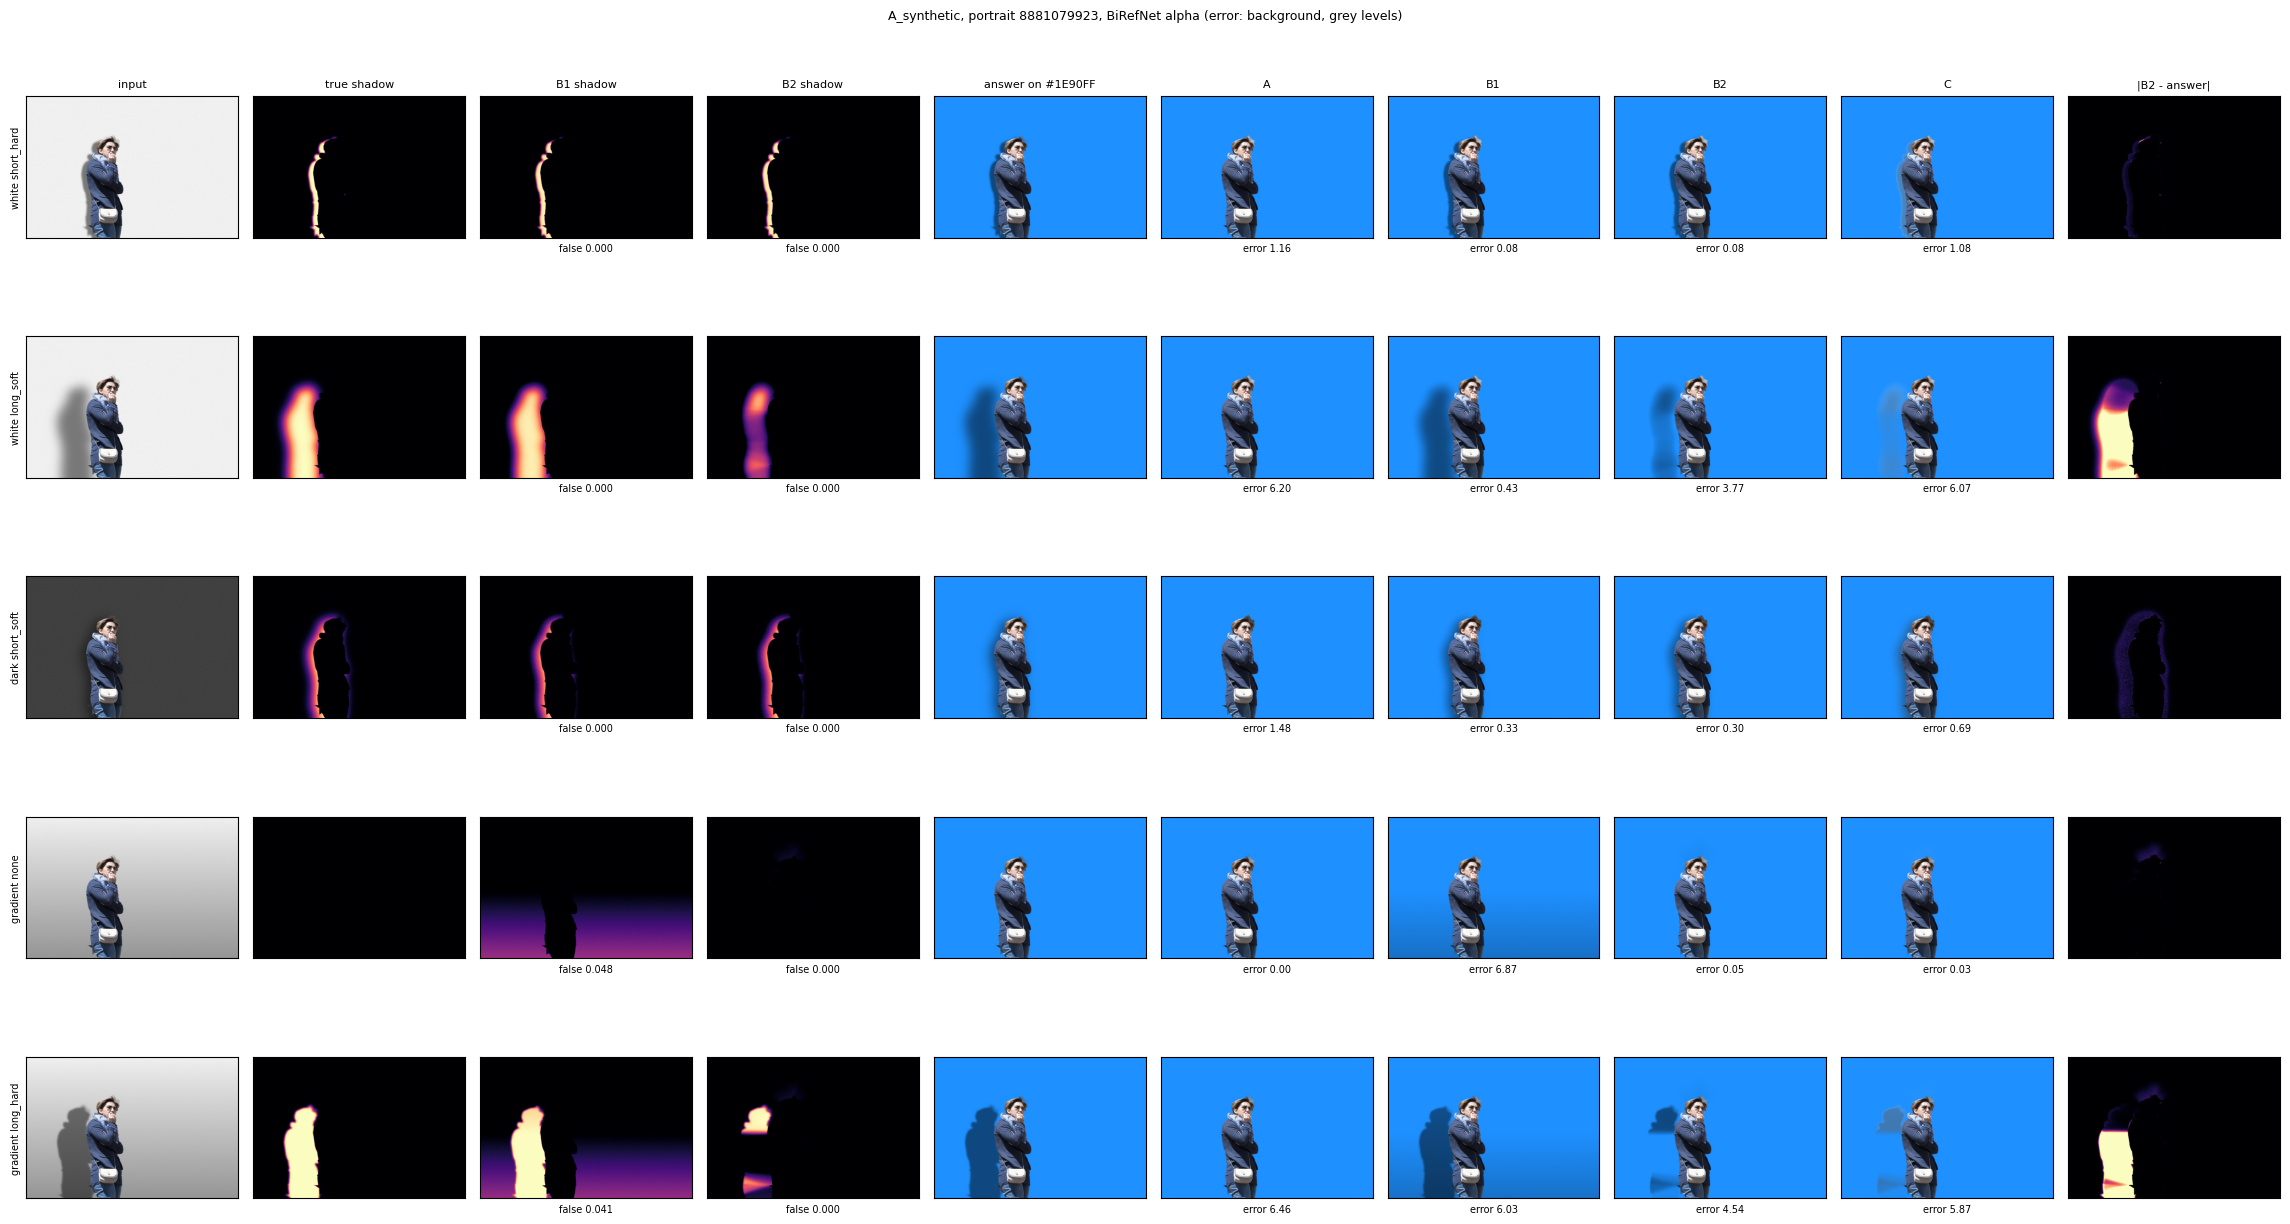

DESOBA figure saved to /content/drive/MyDrive/modelia-e1/results_e3/figures/desoba (not shown: mixed licences)


In [12]:
FIG_COLOUR = NEW_COLOURS[0]
FIG_SETTINGS = ["white short_hard", "white long_soft", "dark short_soft", "gradient none", "gradient long_hard"]
HEAT_MAX = 32  # grey levels: top of the colour scale of the error maps


def pipeline_outputs(x, a, rgb):
    """What the pipeline gives with each method, from an image and an alpha: maps and composites."""
    f = estimate_foreground(x, a)
    maps = {"A": np.ones_like(a), **{m: shadow_map(x, a, how) for m, how in LIT_METHOD.items()}}
    return maps, composites(x, f, a, maps, rgb)


def save_jpeg(img, path, size=1600):
    path.parent.mkdir(parents=True, exist_ok=True)
    Image.fromarray(thumb(u8(img), size)).save(path, quality=92)


rgb = parse_hex(FIG_COLOUR)
main_b2 = colour[(colour["alpha"] == "birefnet") & (colour["colour"] == FIG_COLOUR) & (colour["region"] == "background")
                 & (colour["method"] == "B2") & (colour["group"] == "A_synthetic")]
per_portrait = main_b2.groupby("portrait")["error"].mean().sort_values()
picks = list(dict.fromkeys([per_portrait.index[-1], per_portrait.index[len(per_portrait) // 2]])) if len(per_portrait) else []
for p in picks:
    grid = []
    for s in FIG_SETTINGS:
        hit = synthetic[(synthetic["portrait"] == p) & (synthetic["setting"] == s)]
        if hit.empty:
            continue
        r = hit.iloc[0].to_dict()
        x, a = load_rgb(local(r["image"])), load_alpha16(alpha_path(r))
        t_true = true_shadow(r, a.shape)
        answer = np.asarray(over_colour(load_rgb(local(r["fg"])), load_alpha(local(r["gt"])), rgb, t_true), np.float32)
        maps, outs = pipeline_outputs(x, a, rgb)
        e = colour[(colour["name"] == r["name"]) & (colour["alpha"] == "birefnet") & (colour["colour"] == FIG_COLOUR)
                   & (colour["region"] == "background")].set_index("method")["error"]
        mm = maps_df[(maps_df["name"] == r["name"]) & (maps_df["alpha"] == "birefnet")].set_index("method")
        a_true = load_alpha(local(r["gt"]))
        grid.append((s, [np.asarray(x), ("heat", (1 - a_true) * (1 - t_true), 0.5), ("heat", (1 - a) * (1 - maps["B1"]), 0.5),
                         ("heat", (1 - a) * (1 - maps["B2"]), 0.5), answer, *(outs[m] for m in METHODS),
                         ("heat", np.abs(outs["B2"] - answer).mean(-1) * (a_true < 0.02), HEAT_MAX)],
                     ["", "", f"false {mm.loc['B1', 'false_shadow']:.3f}", f"false {mm.loc['B2', 'false_shadow']:.3f}", "",
                      *(f"error {e[m]:.2f}" for m in METHODS), ""]))
    if grid:
        show_grid(grid, ["input", "true shadow", "B1 shadow", "B2 shadow", f"answer on {FIG_COLOUR}", *METHODS, "|B2 - answer|"],
                  FIGURES / f"e3_A_{p.split('_')[0]}.png",
                  suptitle=f"A_synthetic, portrait {p.split('_')[0]}, BiRefNet alpha (error: background, grey levels)")

# B: the 3 highest and the 3 lowest B2 errors (true mask), saved only
b2 = colour[(colour["group"] == "B_desoba") & (colour["alpha"] == "true") & (colour["colour"] == FIG_COLOUR)
            & (colour["region"] == "background") & (colour["method"] == "B2")].sort_values("error")
chosen = list(dict.fromkeys([*b2["name"].tail(3)[::-1], *b2["name"].head(3)]))
grid = []
for name in chosen:
    r = desoba[desoba["name"] == name].iloc[0].to_dict()
    x, a = load_rgb(local(r["image"])), load_alpha(local(r["gt"]))
    t_true = true_shadow(r, a.shape)
    answer = np.asarray(over_colour(x, a, rgb, t_true), np.float32)
    maps = {"A": np.ones_like(a), **{m: shadow_map(x, a, how) for m, how in LIT_METHOD.items()}}
    outs = composites(x, x, a, maps, rgb)
    err = b2.set_index("name").loc[name, "error"]
    grid.append((name, [np.asarray(x), *(("heat", (1 - a) * (1 - m), 0.5) for m in (t_true, maps["B1"], maps["B2"])),
                        answer, outs["B2"], ("heat", np.abs(outs["B2"] - answer).mean(-1) * (a < 0.02), HEAT_MAX)],
                 ["", "", "", "", "", f"error {err:.2f}", ""]))
if grid:
    show_grid(grid, ["photo", "true shadow", "B1 shadow", "B2 shadow", f"answer on {FIG_COLOUR}", "B2", "|B2 - answer|"],
              FIGURES / "desoba" / "e3_B_extremes.png", show=False, suptitle="DESOBA, true mask: highest (top) and lowest B2 errors")
    print("DESOBA figure saved to", FIGURES / "desoba", "(not shown: mixed licences)")

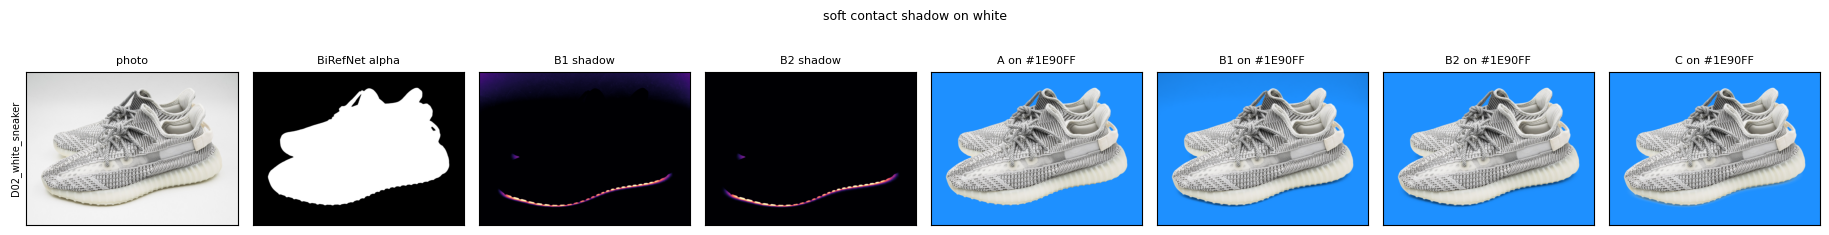

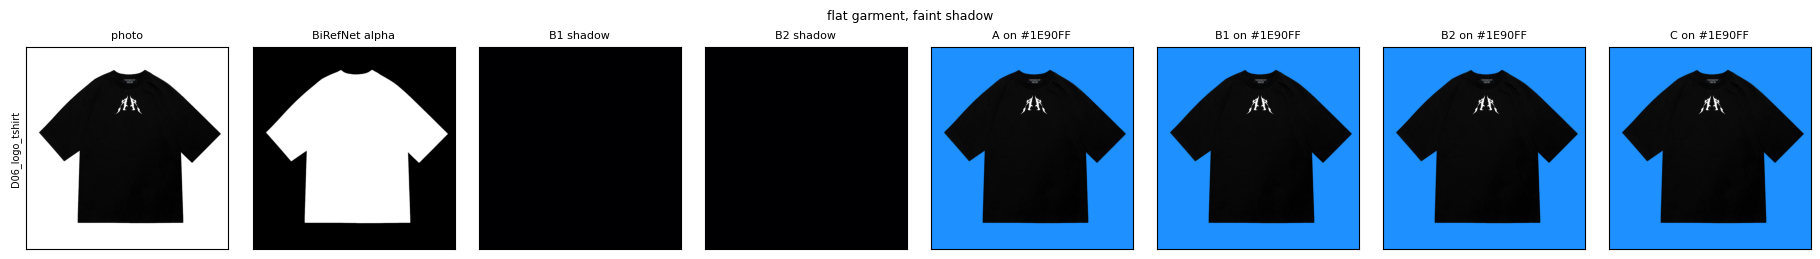

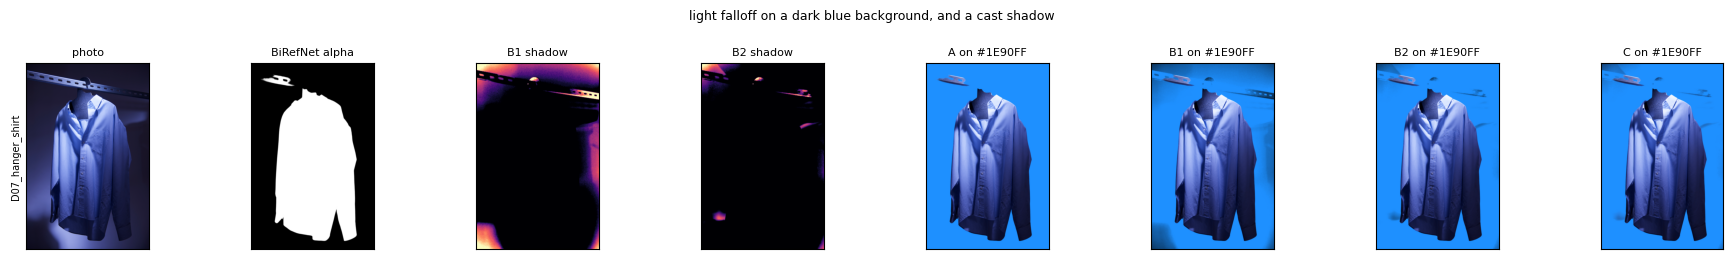

D10_low_light: no known licence, figure saved to /content/drive/MyDrive/modelia-e1/results_e3/figures/real only


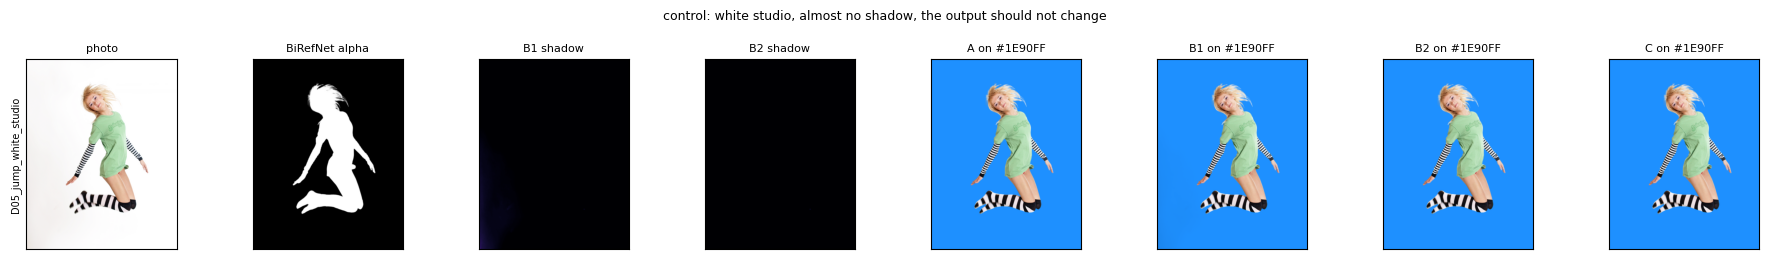

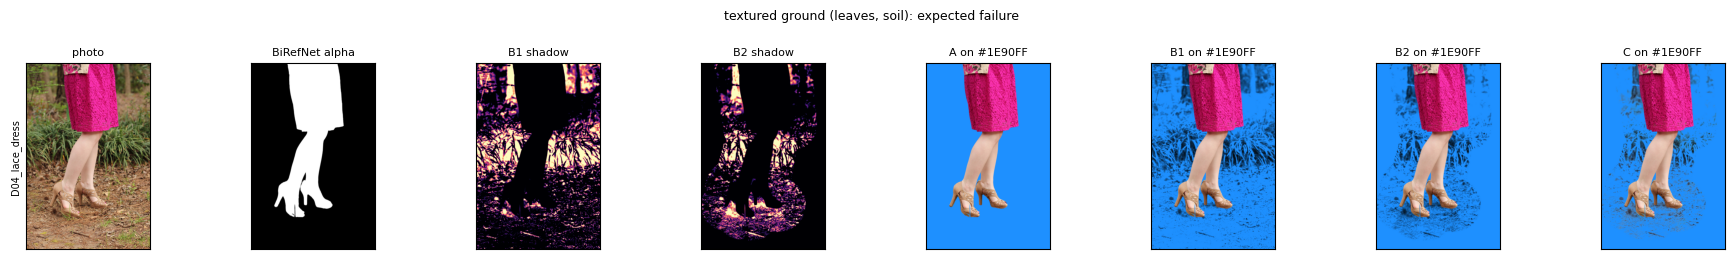

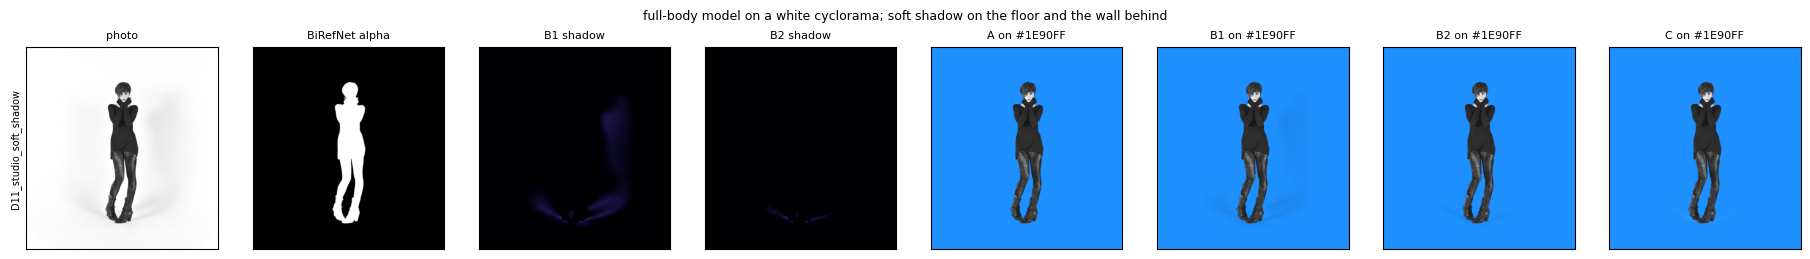

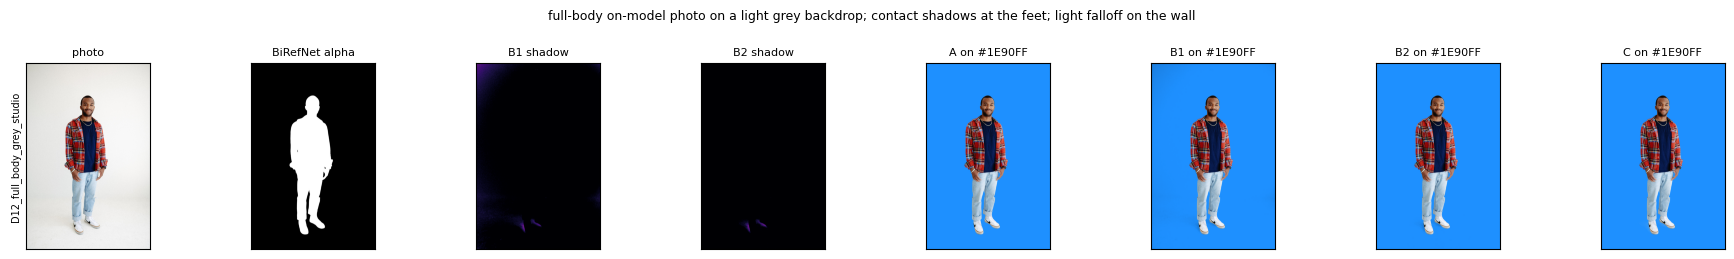

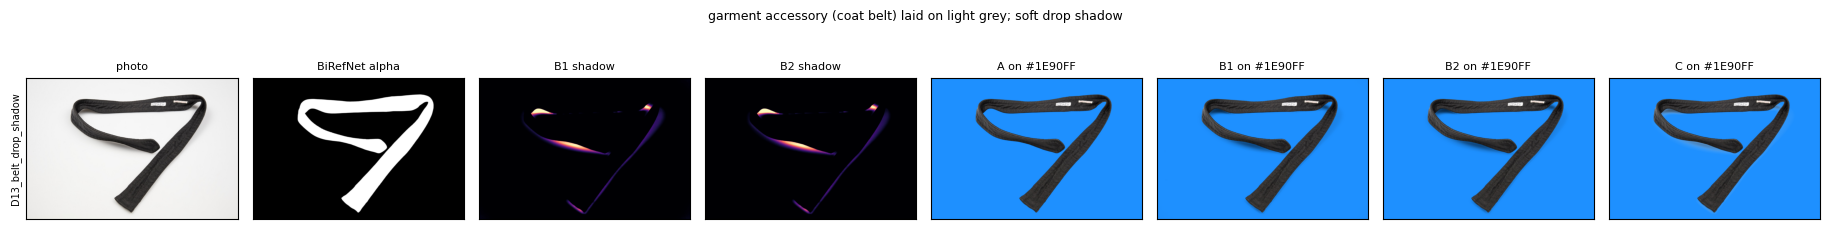

megapixels  seconds  \
name                      method                        
D02_white_sneaker         B1           2.669    0.083   
                          B2           2.669    0.196   
D06_logo_tshirt           B1           3.686    0.195   
                          B2           3.686    0.505   
D07_hanger_shirt          B1           3.020    0.081   
                          B2           3.020    0.214   
D10_low_light             B1           0.426    0.093   
                          B2           0.426    0.208   
D05_jump_white_studio     B1           3.186    0.070   
                          B2           3.186    0.169   
D04_lace_dress            B1           0.614    0.041   
                          B2           0.614    0.173   
D11_studio_soft_shadow    B1           0.534    0.028   
                          B2           0.534    0.165   
D12_full_body_grey_studio B1           5.530    0.075   
                          B2           5.530    0.173   
D13_belt_drop_shadow      B1           2.458    0.051   
                          B2           2.458    0.125   

                                  background darkened (%)  mean darkening  \
name                      method                                            
D02_white_sneaker         B1                       30.821           0.021   
                          B2                        3.549           0.008   
D06_logo_tshirt           B1                        0.000           0.000   
                          B2                        0.000           0.000   
D07_hanger_shirt          B1                       41.947           0.081   
                          B2                        9.199           0.014   
D10_low_light             B1                       45.420           0.140   
                          B2                        5.090           0.011   
D05_jump_white_studio     B1                        6.441           0.003   
                          B2                        0.003           0.000   
D04_lace_dress            B1                       50.518           0.142   
                          B2                       31.967           0.080   
D11_studio_soft_shadow    B1                        8.558           0.004   
                          B2                        0.588           0.000   
D12_full_body_grey_studio B1                       11.119           0.006   
                          B2                        0.456           0.000   
D13_belt_drop_shadow      B1                        4.308           0.007   
                          B2                        4.432           0.007   

                                  mean change from A on white  
name                      method                               
D02_white_sneaker         B1                            5.476  
                          B2                            1.919  
D06_logo_tshirt           B1                            0.000  
                          B2                            0.000  
D07_hanger_shirt          B1                           20.698  
                          B2                            3.484  
D10_low_light             B1                           35.647  
                          B2                            2.842  
D05_jump_white_studio     B1                            0.743  
                          B2                            0.000  
D04_lace_dress            B1                           36.179  
                          B2                           20.469  
D11_studio_soft_shadow    B1                            0.999  
                          B2                            0.070  
D12_full_body_grey_studio B1                            1.532  
                          B2                            0.078  
D13_belt_drop_shadow      B1                            1.686  
                          B2                            1.689

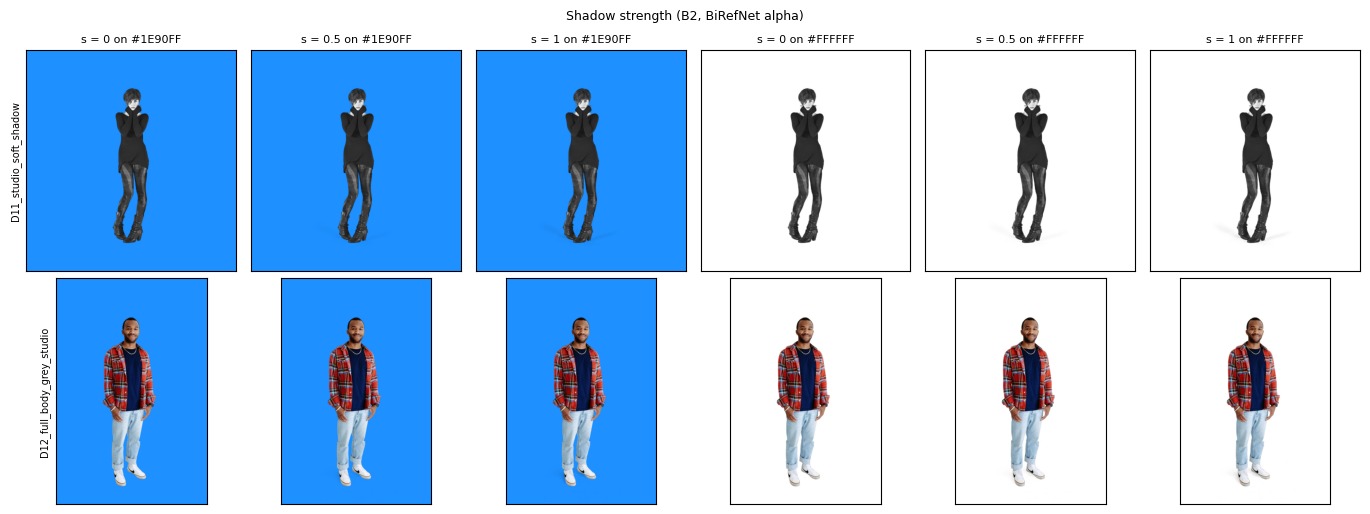

In [13]:
real_rows = []
for r in real.to_dict("records"):
    x, a = load_rgb(local(r["image"])), load_alpha16(alpha_path(r))
    f = estimate_foreground(x, a)
    maps, secs = {"A": np.ones_like(a)}, {}
    for m, how in LIT_METHOD.items():
        t = time.perf_counter()
        maps[m] = shadow_map(x, a, how)
        secs[m] = time.perf_counter() - t
    outs = {c: composites(x, f, a, maps, parse_hex(c)) for c in NEW_COLOURS}
    for c in NEW_COLOURS:
        for m in METHODS:
            save_jpeg(outs[c][m], COMPOSITES / m / f"{r['name']}_{c[1:]}.jpg")
    bg = a < 0.02
    for m in ("B1", "B2"):
        real_rows.append({"name": r["name"], "method": m, "megapixels": x.width * x.height / 1e6, "seconds": secs[m],
                          "background darkened (%)": 100 * float((maps[m][bg] < 0.98).mean()),
                          "mean darkening": float((1 - maps[m][bg]).mean()),
                          "mean change from A on white": float(np.abs(outs["#FFFFFF"][m] - outs["#FFFFFF"]["A"]).mean(-1)[bg].mean())})
    show = "unknown" not in r["source"]
    if not show:
        print(f"{r['name']}: no known licence, figure saved to {FIGURES / 'real'} only")
    show_grid([(r["name"], [np.asarray(x), a, ("heat", (1 - a) * (1 - maps["B1"]), 0.5), ("heat", (1 - a) * (1 - maps["B2"]), 0.5),
                            *(outs[FIG_COLOUR][m] for m in METHODS)], None)],
              ["photo", "BiRefNet alpha", "B1 shadow", "B2 shadow", *(f"{m} on {FIG_COLOUR}" for m in METHODS)],
              FIGURES / "real" / f"{r['name']}.png", show=show, suptitle=r["note"])
real_table = pd.DataFrame(real_rows).set_index(["name", "method"])
real_table.to_csv(RESULTS / "e3_real.csv")
(RESULTS / "e3_real.md").write_text("Real photos, BiRefNet alpha (no ground truth): background = alpha < 0.02.\n\n"
                                    + md_table(real_table.reset_index().set_index("name"), "{:.3f}"), encoding="utf-8")
display(real_table.round(3))

# Strength on two studio photos (B2): 0 = no shadow, 1 = the measured shadow
grid = []
for name in ("D11_studio_soft_shadow", "D12_full_body_grey_studio"):
    hit = real[real["name"] == name]
    if hit.empty:
        continue
    r = hit.iloc[0].to_dict()
    x, a = load_rgb(local(r["image"])), load_alpha16(alpha_path(r))
    f, t = estimate_foreground(x, a), shadow_map(x, a, "inpaint")
    grid.append((name, [np.asarray(over_colour(f, a, parse_hex(c), with_strength(t, s))) for c in (FIG_COLOUR, "#FFFFFF") for s in (0, 0.5, 1)], None))
if grid:
    show_grid(grid, [f"s = {s} on {c}" for c in (FIG_COLOUR, "#FFFFFF") for s in (0, 0.5, 1)], FIGURES / "e3_strength_D.png",
              suptitle="Shadow strength (B2, BiRefNet alpha)")

## 9. Speed

BiRefNet: median seconds per image on the device above. On CPU: the foreground estimation (as in E2) and the shadow maps, per image, from the runs of section 4 (BiRefNet's alpha) and of section 8 (the real photos, up to 5.5 MP).

In [14]:
bt = pd.read_csv(timing_csv) if timing_csv.exists() else pd.DataFrame(columns=["device", "hardware", "megapixels", "seconds", "load_seconds"])
mb = maps_df[(maps_df["alpha"] == "birefnet") & maps_df["method"].isin(["B1", "B2"])]
speed = [{"step": f"BiRefNet on {dev}", "hardware": hw, "images": len(d), "median megapixels": d["megapixels"].median(),
          "median s": d["seconds"].median(), "max s": d["seconds"].max(), "first call s": d["load_seconds"].iloc[0]}
         for (dev, hw), d in bt.groupby(["device", "hardware"])]
fg = mb.drop_duplicates("name")
speed.append({"step": "foreground estimation", "hardware": CPU, "images": len(fg), "median megapixels": fg["megapixels"].median(),
              "median s": fg["fg_seconds"].median(), "max s": fg["fg_seconds"].max(), "first call s": FG_FIRST_CALL_S})
rt = real_table.reset_index()
for m, how in LIT_METHOD.items():
    d = pd.concat([mb[mb["method"] == m][["megapixels", "seconds"]], rt[rt["method"] == m][["megapixels", "seconds"]]])
    speed.append({"step": f"shadow map {m} ({how})", "hardware": CPU, "images": len(d), "median megapixels": d["megapixels"].median(),
                  "median s": d["seconds"].median(), "max s": d["seconds"].max(), "first call s": np.nan})
speed = pd.DataFrame(speed).set_index("step")
speed.to_csv(RESULTS / "e3_speed.csv")
(RESULTS / "e3_speed.md").write_text(md_table(speed, "{:.2f}") + "\n\n`first call s`: loading BiRefNet, or the first "
                                     "foreground estimation of the session (numba compile or cache load).", encoding="utf-8")
display(speed.round(2))

,hardware,images,median megapixels,median s,max s,first call s
step,,,,,,
BiRefNet on cuda,Tesla T4,268,0.7,0.45,0.50,31.41
foreground estimation,Intel(R) Xeon(R) CPU @ 2.00GHz (2 threads),259,0.7,0.26,1.01,47.54
shadow map B1 (flat),Intel(R) Xeon(R) CPU @ 2.00GHz (2 threads),268,0.7,0.05,0.20,NaN
shadow map B2 (inpaint),Intel(R) Xeon(R) CPU @ 2.00GHz (2 threads),268,0.7,0.14,0.51,NaN


## 10. The numbers for each hypothesis

Measured values only: the verdicts are written in section 11 and in `EXPERIMENTS.md` after looking at these and at the figures.

In [15]:
def mean_of(df, **eq):
    d = df
    for k, v in eq.items():
        d = d[d[k].isin(v) if isinstance(v, (list, tuple)) else d[k] == v]
    return d


def fmt(v, f="{:.3f}"):
    return "n/a" if v is None or (isinstance(v, float) and np.isnan(v)) else f.format(v)


mt, mb_ = maps_df[maps_df["alpha"] == "true"], maps_df[maps_df["alpha"] == "birefnet"]
out = []

h1 = mean_of(mt, group="A_synthetic", background=["white", "dark"], shadow_kind=["short_hard", "short_soft"])
out.append("H1 true alpha, white and dark, short shadows: shadow MAE " + "; ".join(
    f"{m} {fmt(h1[h1['method'] == m]['shadow_mae'].mean())} (per setting {', '.join(fmt(v) for v in h1[h1['method'] == m].groupby('setting')['shadow_mae'].mean())})"
    for m in ("B1", "B2")) + " (threshold 0.03)")

h2 = mean_of(mt, group="A_synthetic", background="gradient")
out.append("H2 gradient, true alpha, false shadow on the lit background: " + "; ".join(
    f"{m} {fmt(h2[h2['method'] == m]['false_shadow'].mean())}" for m in ("B1", "B2")) + " (B1 > 0.05, B2 < 0.02 expected)")

h3 = mean_of(mt, group="A_synthetic", background=["white", "dark"], shadow_kind=["long_hard", "long_soft"])
w3 = h3.pivot_table(index="name", columns="method", values="shadow_bias")
out.append("H3 long shadows, white and dark, true alpha, bias in the shadow pixels: " + "; ".join(
    f"{m} {fmt(h3[h3['method'] == m]['shadow_bias'].mean(), '{:+.3f}')}" for m in ("B1", "B2"))
    + (f"; B2 bias above B1's on {int((w3['B2'] > w3['B1']).sum())}/{len(w3)} inputs" if len(w3) else ""))

cs = mean_of(colour, alpha="true", method="C*", region="shadow", group="A_synthetic").dropna(subset=["error"])
cb = mean_of(colour, alpha="birefnet", region="background", colour=NEW_COLOURS[0], group="A_synthetic")
cb = cb[cb["shadow_kind"] != "none"].pivot_table(index="name", columns="method", values="error")
out.append(f"H4 C with the true T, shadow pixels: measured {fmt(cs['error'].mean(), '{:.2f}')} vs predicted T(1-T)L "
           f"{fmt(cs['predicted'].mean(), '{:.2f}')} levels (largest per-image gap {fmt((cs['error'] - cs['predicted']).abs().max(), '{:.2f}')}); "
           + (f"C worse than B2 (BiRefNet alpha, background, {NEW_COLOURS[0]}) on {int((cb['C'] > cb['B2']).sum())}/{len(cb)} inputs with a shadow" if len(cb) else ""))

sh5 = on_shadows[on_shadows["group"] == "A_synthetic"]
c5 = mean_of(colour, method="B2", region="shadow", colour=NEW_COLOURS[0], group="A_synthetic").pivot_table(index="name", columns="alpha", values="error")
out.append(f"H5 BiRefNet on the synthetic shadows: mean alpha {fmt(sh5['mean alpha on shadow px'].mean(), '{:.4f}')} "
           f"(highest per setting {fmt(sh5.groupby(['background', 'shadow_kind'])['mean alpha on shadow px'].mean().max(), '{:.4f}')}; threshold 0.05); "
           + (f"B2 error in the shadow pixels, BiRefNet minus true alpha: mean {fmt((c5['birefnet'] - c5['true']).mean(), '{:+.2f}')} levels, "
              f"largest {fmt((c5['birefnet'] - c5['true']).max(), '{:+.2f}')} (threshold 2)" if len(c5) else ""))

out.append("H6 shadow map seconds per image on CPU: " + "; ".join(
    f"{s}: median {fmt(speed.loc[s, 'median s'], '{:.2f}')}, max {fmt(speed.loc[s, 'max s'], '{:.2f}')}" for s in speed.index if s.startswith("shadow map"))
    + " (threshold 1 s)")

h7 = mean_of(mb_, group="A_synthetic", shadow_kind="none")
h7t = mean_of(mt, group="A_synthetic", shadow_kind="none")
out.append("H7 no-shadow controls, false shadow B2: BiRefNet alpha " + ", ".join(
    f"{bg} {fmt(h7[(h7['method'] == 'B2') & (h7['background'] == bg)]['false_shadow'].mean(), '{:.4f}')}" for bg in BACKGROUNDS)
    + "; true alpha " + ", ".join(f"{bg} {fmt(h7t[(h7t['method'] == 'B2') & (h7t['background'] == bg)]['false_shadow'].mean(), '{:.4f}')}"
                                  for bg in BACKGROUNDS) + " (threshold 0.01)")

b8 = mean_of(colour, group="B_desoba", alpha="true", region="shadow", colour=NEW_COLOURS[0]).pivot_table(index="name", columns="method", values="error")
f8 = mean_of(mt, method="B2")
out.append((f"H8 DESOBA, true mask, shadow pixels: B2 better than A on {int((b8['B2'] < b8['A']).sum())}/{len(b8)} photos "
            f"(A {fmt(b8['A'].mean(), '{:.2f}')}, B2 {fmt(b8['B2'].mean(), '{:.2f}')} levels); " if len(b8) else "H8 no DESOBA rows; ")
           + f"B2 false shadow on the lit pixels: DESOBA {fmt(f8[f8['group'] == 'B_desoba']['false_shadow'].mean(), '{:.4f}')} vs "
             f"A_synthetic {fmt(f8[f8['group'] == 'A_synthetic']['false_shadow'].mean(), '{:.4f}')}; other objects' shadows kept: "
             f"{fmt(f8[f8['group'] == 'B_desoba']['other_kept'].mean(), '{:.3f}')} mean darkening")

d05 = real_table.loc["D05_jump_white_studio"] if "D05_jump_white_studio" in real_table.index.get_level_values(0) else None
out.append("H9 real photos: by eye (figures/real/); " + (
    f"D05 mean change from A on white: B1 {fmt(d05.loc['B1', 'mean change from A on white'], '{:.2f}')}, "
    f"B2 {fmt(d05.loc['B2', 'mean change from A on white'], '{:.2f}')} levels (threshold 2)" if d05 is not None else "D05 not in this run"))

(RESULTS / "e3_hypotheses_numbers.md").write_text("\n".join(f"- {line}" for line in out), encoding="utf-8")
print("\n".join(out))

H1 true alpha, white and dark, short shadows: shadow MAE B1 0.028 (per setting 0.027, 0.030, 0.026, 0.029); B2 0.027 (per setting 0.026, 0.026, 0.026, 0.027) (threshold 0.03)
H2 gradient, true alpha, false shadow on the lit background: B1 0.037; B2 0.005 (B1 > 0.05, B2 < 0.02 expected)
H3 long shadows, white and dark, true alpha, bias in the shadow pixels: B1 +0.022; B2 +0.135; B2 bias above B1's on 52/60 inputs
H4 C with the true T, shadow pixels: measured 28.63 vs predicted T(1-T)L 28.65 levels (largest per-image gap 0.21); C worse than B2 (BiRefNet alpha, background, #1E90FF) on 180/180 inputs with a shadow
H5 BiRefNet on the synthetic shadows: mean alpha 0.0006 (highest per setting 0.0023; threshold 0.05); B2 error in the shadow pixels, BiRefNet minus true alpha: mean +1.45 levels, largest +21.88 (threshold 2)
H6 shadow map seconds per image on CPU: shadow map B1 (flat): median 0.05, max 0.20; shadow map B2 (inpaint): median 0.14, max 0.51 (threshold 1 s)
H7 no-shadow controls, fal

## 11. Result and decision

Full entry: `EXPERIMENTS.md`, E3.

- **Chosen: B2** (lit background inpainted in a band of 10 % of the diagonal around the subject) for `--keep-shadows`, **off by default**, strength 1 by default; B1 stays available as `--shadow-method flat`. Dead zone (3 %) and band unchanged.
- **B1 vs B2 tie** on the 225 synthetic inputs (2.43 vs 2.47 grey levels, BiRefNet alpha, `#1E90FF`; B2 better on 10 of 15 portraits, p = 0.72). The tie-break of the rule points to B1, but B1 fails the rule's studio-backdrop condition: a false shadow of 0.037 on the gradient (threshold 0.02), and 42-45 % of the backdrop darkened on D07 and D10, where the light falls off. I applied that exclusion first, so B2.
- **Where each one fails**: B2 cuts shadows longer than its band (long shadows on plain backgrounds: 5.19 vs 0.78 levels for B1; bias +0.135); B1 takes light falloff for a shadow (6.81 levels on a gradient without any shadow, B2 0.88). Both copy texture (D04; DESOBA lit pixels: B1 13.5, B2 2.9 levels).
- **Off by default**: keeping shadows adds error where there is none (gradient, no shadow: 0.88 vs 0.02) and gives no gain on textured backgrounds (DESOBA as a whole: B2 6.71 vs 6.19 for no shadow, p = 0.48), although B2 halves the error in the shadow pixels (42.6 vs 83.9; better on 34/34).
- **C ruled out**: worse than B2 on 180/180 synthetic inputs with a shadow; its error is the predicted leak $T(1-T)L$ (28.63 measured vs 28.65 predicted).
- **BiRefNet keeps the shadow out of the subject** (mean alpha 0.0006 on the synthetic shadow pixels): with a perfect shadow map (B\*) the error would be 0.02 levels, so the shadow map is what is left to improve.
- Hypotheses 1 (at the edge), 3, 4, 6, 7, 8 and 9 confirmed; 2 partly (B1's false shadow is 0.037, not above 0.05); 5 confirmed for the alpha, partly for the colour (above 2 levels on 30 of 180 inputs, all long shadows).